<a href="https://colab.research.google.com/github/arafatro/IntroToDS/blob/main/Practice%20Materials/Week%2010/DS_Practice_UnsupervisedClustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/arafatro/IntroToDS/blob/main/Practice%20Materials/Week%20X/DS_Practice_UnsupervisedClustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Introduction to Data Science
## Practice Session: Unsupervised Learning: Clustering
**Eötvös Loránd University (ELTE) · Faculty of Informatics**

---
**Instructor:** Arafat Md Easin  
**Goal:** By the end of this session you will be able to:
- Explain what **clustering** does and why **feature scaling** is mandatory before it
- Apply **K-Means, Hierarchical (Agglomerative), DBSCAN, and Gaussian Mixture** clustering
- Choose the number of clusters with the **elbow method, silhouette score, BIC, and stability**
- Know which algorithm fits which **cluster shape** (spherical, elongated, non-convex, noisy)
- Evaluate clusters with **internal and external metrics** and **profile** them to tell a story

> **Tip:** Run each cell with `Shift + Enter` and read the comments carefully before moving on.  
> **Key principle:** There is no ground truth in clustering. Every result depends on your scaling, your algorithm, and your choice of k, so you must justify all three and check the clusters actually mean something.

---

## Part 0: Setup & Datasets

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import load_wine, load_breast_cancer, make_blobs, make_moons, make_circles
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (
    silhouette_score, silhouette_samples, davies_bouldin_score,
    calinski_harabasz_score, adjusted_rand_score, normalized_mutual_info_score
)
from scipy.cluster.hierarchy import linkage, dendrogram

# ── Reproducible randomness ───────────────────────────────────────────
RNG = np.random.default_rng(seed=42)

# ── Plot style ────────────────────────────────────────────────────────
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"]     = 110
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

print("Setup complete.")

Setup complete.


In [ ]:
# ── Load datasets ─────────────────────────────────────────────────────
# We use two classic sklearn datasets:
#   wine          - 13 chemical features, 3 cultivars  (used for the demos)
#   breast_cancer - 30 features, malignant / benign   (used for the exercises)
#
# IMPORTANT: clustering never sees the labels. We keep them ONLY to check, after the fact,
# whether the clusters we found match a known grouping. Real clustering problems have no such labels.

# Wine dataset
wine = load_wine()
X_wine = pd.DataFrame(wine.data, columns=wine.feature_names)
y_wine = pd.Series(wine.target, name="cultivar")

# Breast Cancer dataset
bc = load_breast_cancer()
X_bc = pd.DataFrame(bc.data, columns=bc.feature_names)
y_bc = pd.Series(bc.target, name="target")   # 0 = malignant, 1 = benign

print("=== Wine ===")
print(f"  Samples: {X_wine.shape[0]},  Features: {X_wine.shape[1]}")
print(f"  Hidden classes: {dict(zip(map(str, wine.target_names), map(int, np.bincount(y_wine))))}")
print()
print("=== Breast Cancer ===")
print(f"  Samples: {X_bc.shape[0]},  Features: {X_bc.shape[1]}")
print(f"  Hidden classes: {dict(zip(map(str, bc.target_names), map(int, np.bincount(y_bc))))}")
print()
X_wine.describe().round(2)

=== Wine ===
  Samples: 178,  Features: 13
  Hidden classes: {'class_0': 59, 'class_1': 71, 'class_2': 48}

=== Breast Cancer ===
  Samples: 569,  Features: 30
  Hidden classes: {'malignant': 212, 'benign': 357}



,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00
mean,13.00,2.34,2.37,19.49,99.74,2.30,2.03,0.36,1.59,5.06,0.96,2.61,746.89
std,0.81,1.12,0.27,3.34,14.28,0.63,1.00,0.12,0.57,2.32,0.23,0.71,314.91
min,11.03,0.74,1.36,10.60,70.00,0.98,0.34,0.13,0.41,1.28,0.48,1.27,278.00
25%,12.36,1.60,2.21,17.20,88.00,1.74,1.20,0.27,1.25,3.22,0.78,1.94,500.50
50%,13.05,1.87,2.36,19.50,98.00,2.36,2.13,0.34,1.56,4.69,0.96,2.78,673.50
75%,13.68,3.08,2.56,21.50,107.00,2.80,2.88,0.44,1.95,6.20,1.12,3.17,985.00
max,14.83,5.80,3.23,30.00,162.00,3.88,5.08,0.66,3.58,13.00,1.71,4.00,1680.00


---
## Part 1: What Is Clustering, and Why Scaling Comes First

**Clustering** groups samples so that points in the same cluster are **similar** and points in different clusters are **different**, using only the features. There is no target variable.

Typical uses: customer segmentation, grouping documents, finding species or sub-types, compressing data, detecting anomalies.

| Question | Why it is hard |
|---|---|
| **What does "similar" mean?** | Almost all algorithms use **distance**, so the answer depends entirely on your feature scales |
| **How many clusters are there?** | Usually unknown; you must estimate it |
| **Are the clusters real?** | Every algorithm returns clusters, even on random noise |

> **Scaling is not optional.** A feature measured in the hundreds (like `proline` in the wine data) will dominate Euclidean distance over a feature measured in fractions, and the algorithm will effectively cluster on that single column.

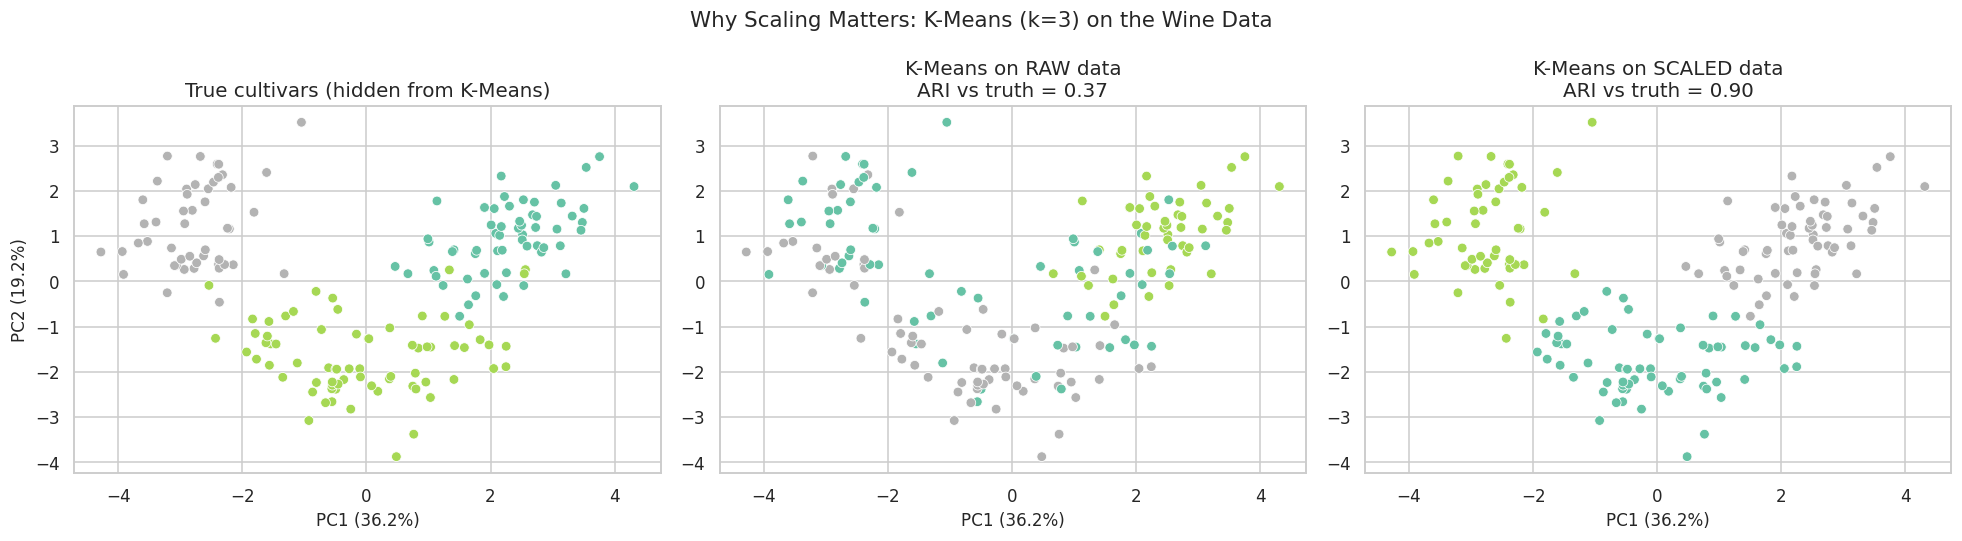

Largest raw std:  proline = 314.9
Typical other std: 0.76

ARI (Adjusted Rand Index): 1.0 = perfect agreement with the truth, 0 = random labelling.
On raw data K-Means is essentially clustering on one column. Scaling fixes that.


In [ ]:
# ── 1.1  K-Means on raw vs scaled wine data ──────────────────────────
# Same algorithm, same k=3. The only difference is StandardScaler.

X_wine_sc = pd.DataFrame(StandardScaler().fit_transform(X_wine), columns=X_wine.columns)

km_raw    = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X_wine)
km_scaled = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X_wine_sc)

# 2D view for plotting (PCA fitted on the scaled data for every panel, so the axes are comparable)
pca2 = PCA(n_components=2, random_state=42).fit(X_wine_sc)
P    = pca2.transform(X_wine_sc)

ari_raw    = adjusted_rand_score(y_wine, km_raw.labels_)
ari_scaled = adjusted_rand_score(y_wine, km_scaled.labels_)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Why Scaling Matters: K-Means (k=3) on the Wine Data", fontsize=14)

panels = [("True cultivars (hidden from K-Means)", y_wine.values, None),
          (f"K-Means on RAW data\nARI vs truth = {ari_raw:.2f}",   km_raw.labels_, None),
          (f"K-Means on SCALED data\nARI vs truth = {ari_scaled:.2f}", km_scaled.labels_, None)]
for ax, (title, lab, _) in zip(axes, panels):
    sc = ax.scatter(P[:, 0], P[:, 1], c=lab, cmap="Set2", s=40, edgecolors="white", linewidth=0.5)
    ax.set_title(title)
    ax.set_xlabel(f"PC1 ({pca2.explained_variance_ratio_[0]*100:.1f}%)")
    ax.set_ylabel(f"PC2 ({pca2.explained_variance_ratio_[1]*100:.1f}%)" if ax == axes[0] else "")

plt.tight_layout()
plt.show()

stds = X_wine.std().sort_values(ascending=False)
print(f"Largest raw std:  {stds.index[0]} = {stds.iloc[0]:.1f}")
print(f"Typical other std: {stds.iloc[1:].median():.2f}")
print(f"\nARI (Adjusted Rand Index): 1.0 = perfect agreement with the truth, 0 = random labelling.")
print("On raw data K-Means is essentially clustering on one column. Scaling fixes that.")

---
## Part 2: K-Means

**K-Means** partitions the data into $k$ clusters, each represented by its **centroid** (mean). The algorithm (Lloyd's):

1. Pick $k$ initial centroids.
2. **Assign** every point to its nearest centroid.
3. **Update** each centroid to the mean of its assigned points.
4. Repeat 2 and 3 until assignments stop changing.

It minimises the **inertia** (within-cluster sum of squared distances): $\sum_i \lVert x_i - \mu_{c(i)} \rVert^2$.

| Strength | Weakness |
|---|---|
| Fast, simple, scales to large data | You must choose $k$ in advance |
| Works well for compact, round clusters of similar size | Fails on elongated, non-convex, or very different-sized clusters |
| Easy to interpret via centroids | Sensitive to initialisation and to outliers |

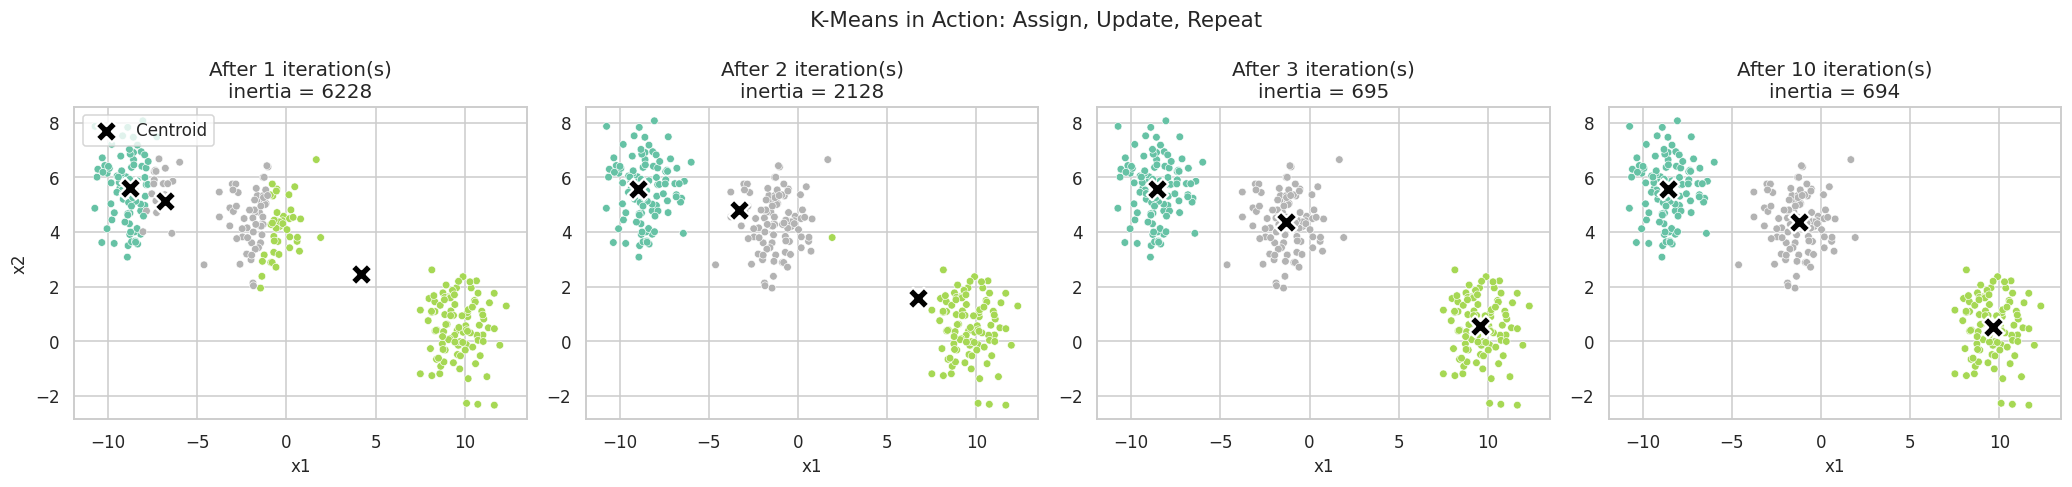

Centroids move toward the middle of their points, assignments change, inertia falls, then it stabilises.


In [ ]:
# ── 2.1  Watch K-Means iterate ───────────────────────────────────────
# We start from a deliberately poor set of initial centroids and freeze the algorithm
# after 1, 2, 3 and 10 iterations.

Xd, _ = make_blobs(n_samples=300, centers=3, cluster_std=1.1, random_state=7)
init  = Xd[np.random.default_rng(1).choice(len(Xd), 3, replace=False)]

fig, axes = plt.subplots(1, 4, figsize=(19, 4.5))
fig.suptitle("K-Means in Action: Assign, Update, Repeat", fontsize=14)

for ax, it in zip(axes, [1, 2, 3, 10]):
    km = KMeans(n_clusters=3, init=init, n_init=1, max_iter=it, algorithm="lloyd").fit(Xd)
    ax.scatter(Xd[:, 0], Xd[:, 1], c=km.labels_, cmap="Set2", s=25, edgecolors="white", linewidth=0.4)
    ax.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1], c="black", marker="X", s=200,
               edgecolors="white", linewidth=1.5, label="Centroid")
    ax.set_title(f"After {it} iteration(s)\ninertia = {km.inertia_:.0f}")
    ax.set_xlabel("x1")
    ax.set_ylabel("x2" if ax == axes[0] else "")
axes[0].legend(loc="upper left")

plt.tight_layout()
plt.show()

print("Centroids move toward the middle of their points, assignments change, inertia falls, then it stabilises.")

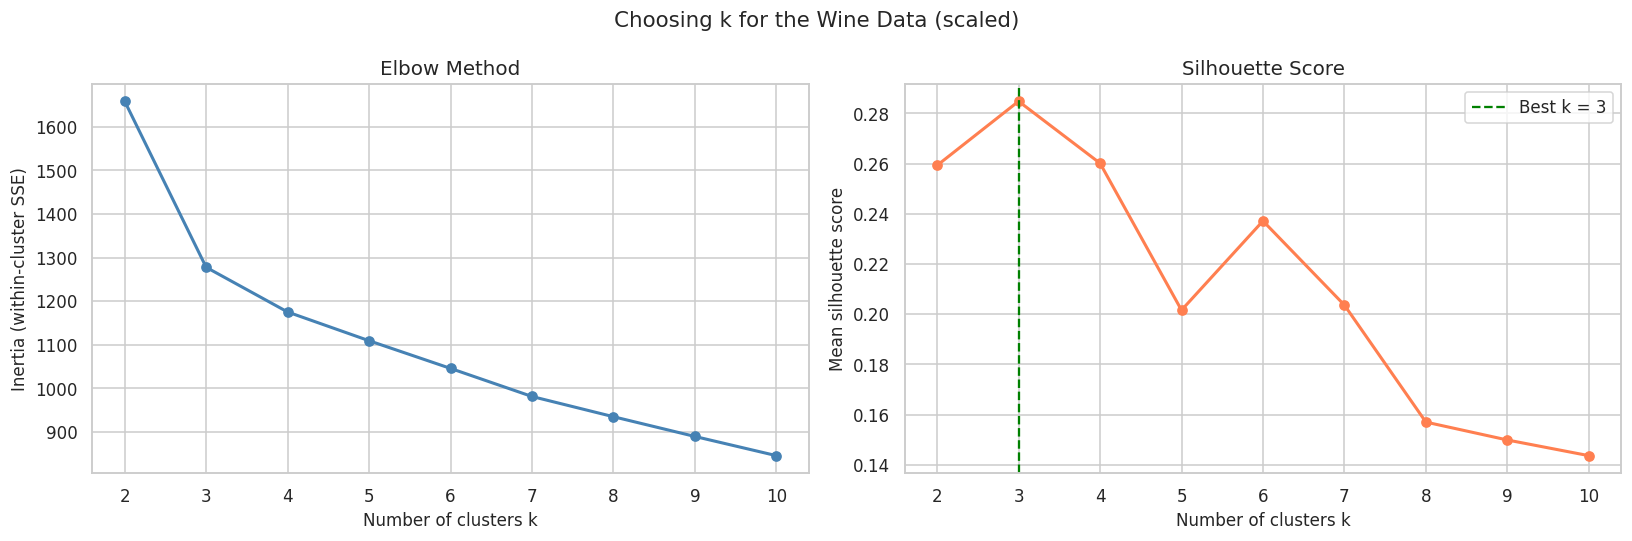

Best k by silhouette: 3  (score = 0.285)
The elbow is often ambiguous; the silhouette peak is usually easier to read. Use both, plus domain knowledge.


In [ ]:
# ── 2.2  Choosing k: elbow and silhouette ────────────────────────────
# Inertia always decreases as k grows, so look for the "elbow" where gains flatten.
# Silhouette measures how well each point fits its own cluster vs the nearest other one
# (range -1 to 1, higher is better) and has a clear peak.

ks = range(2, 11)
inertias, sils = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_wine_sc)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X_wine_sc, km.labels_))

best_k_sil = list(ks)[int(np.argmax(sils))]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle("Choosing k for the Wine Data (scaled)", fontsize=14)

axes[0].plot(list(ks), inertias, "o-", color="steelblue", linewidth=2)
axes[0].set_xlabel("Number of clusters k")
axes[0].set_ylabel("Inertia (within-cluster SSE)")
axes[0].set_title("Elbow Method")

axes[1].plot(list(ks), sils, "o-", color="coral", linewidth=2)
axes[1].axvline(best_k_sil, color="green", linestyle="--", linewidth=1.5, label=f"Best k = {best_k_sil}")
axes[1].set_xlabel("Number of clusters k")
axes[1].set_ylabel("Mean silhouette score")
axes[1].set_title("Silhouette Score")
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Best k by silhouette: {best_k_sil}  (score = {max(sils):.3f})")
print("The elbow is often ambiguous; the silhouette peak is usually easier to read. Use both, plus domain knowledge.")

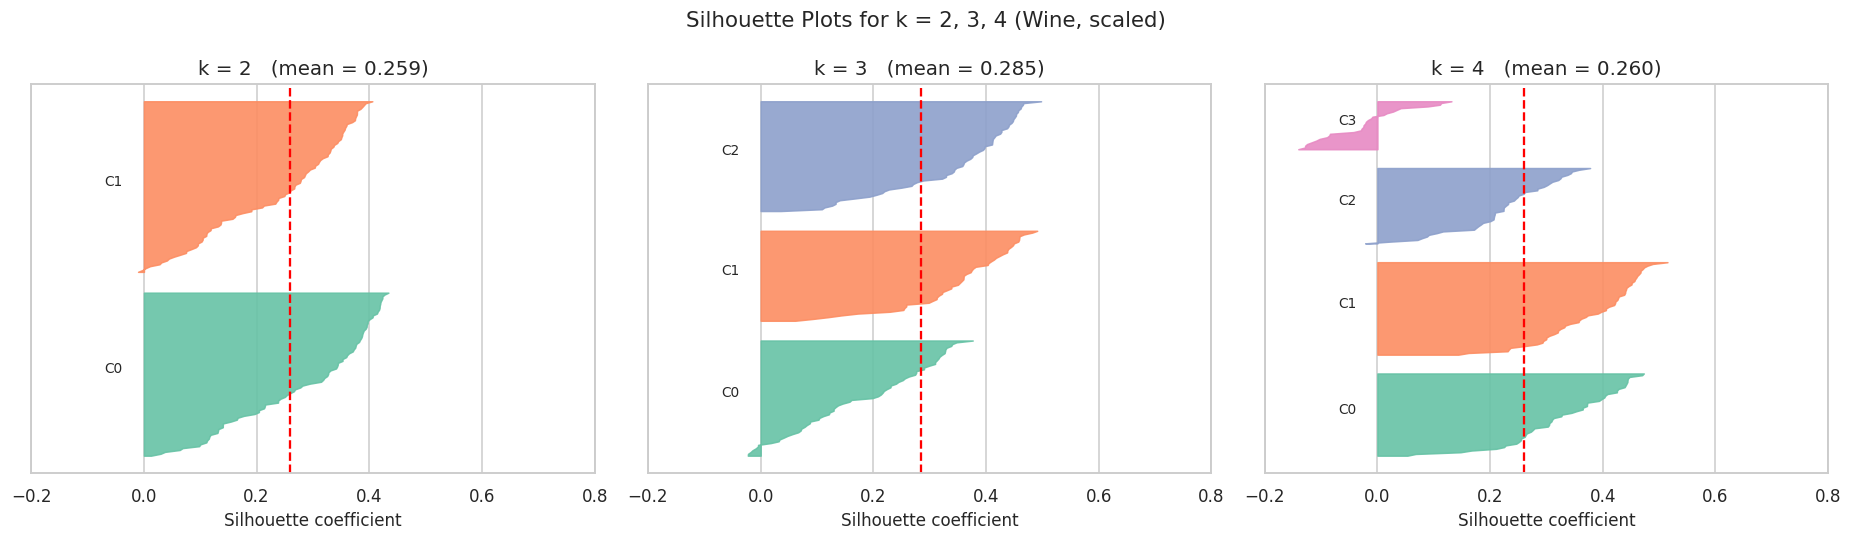

Points with negative silhouette are closer to another cluster than to their own: likely mis-assigned.


In [ ]:
# ── 2.3  Silhouette plots: look inside each cluster ──────────────────
# One horizontal bar per sample, grouped by cluster. Good clusters: wide, uniform blades
# that extend beyond the average (red line). Bad clusters: thin blades or negative values.

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
fig.suptitle("Silhouette Plots for k = 2, 3, 4 (Wine, scaled)", fontsize=14)

for ax, k in zip(axes, [2, 3, 4]):
    km  = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_wine_sc)
    s   = silhouette_samples(X_wine_sc, km.labels_)
    avg = s.mean()
    y_lower = 10
    for c in range(k):
        sc_c = np.sort(s[km.labels_ == c])
        y_upper = y_lower + len(sc_c)
        ax.fill_betweenx(np.arange(y_lower, y_upper), 0, sc_c, color=plt.cm.Set2(c), alpha=0.9)
        ax.text(-0.07, y_lower + len(sc_c) / 2, f"C{c}", fontsize=9)
        y_lower = y_upper + 10
    ax.axvline(avg, color="red", linestyle="--", linewidth=1.5)
    ax.set_title(f"k = {k}   (mean = {avg:.3f})")
    ax.set_xlabel("Silhouette coefficient")
    ax.set_yticks([])
    ax.set_xlim(-0.2, 0.8)

plt.tight_layout()
plt.show()

print("Points with negative silhouette are closer to another cluster than to their own: likely mis-assigned.")

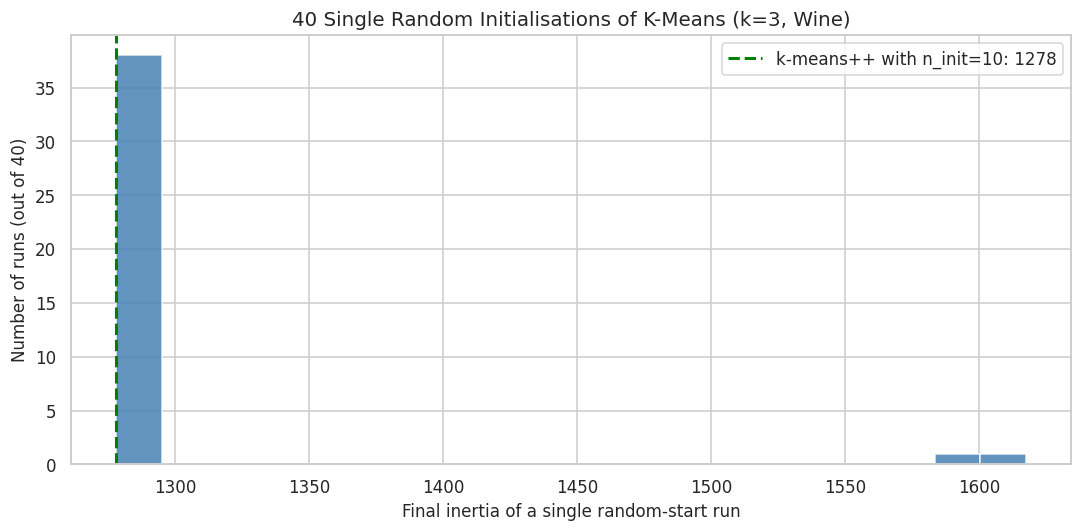

2 of 40 single runs ended more than 1% above the best inertia (worst = 1617).
Always use n_init > 1 (the default init is k-means++), and fix random_state for reproducibility.


In [ ]:
# ── 2.4  K-Means is sensitive to initialisation ──────────────────────
# A single run from a random start can land in a poor local minimum.
# Running several starts (n_init) and keeping the best fixes this.
# sklearn's default init="k-means++" also spreads the starting centroids out.

single_runs = [KMeans(n_clusters=3, init="random", n_init=1, random_state=s).fit(X_wine_sc).inertia_
               for s in range(40)]
best_run    = KMeans(n_clusters=3, init="k-means++", n_init=10, random_state=42).fit(X_wine_sc).inertia_

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(single_runs, bins=20, color="steelblue", edgecolor="white", alpha=0.85)
ax.axvline(best_run, color="green", linestyle="--", linewidth=2, label=f"k-means++ with n_init=10: {best_run:.0f}")
ax.set_xlabel("Final inertia of a single random-start run")
ax.set_ylabel("Number of runs (out of 40)")
ax.set_title("40 Single Random Initialisations of K-Means (k=3, Wine)")
ax.legend()
plt.tight_layout()
plt.show()

worse = int(np.sum(np.array(single_runs) > best_run * 1.01))
print(f"{worse} of 40 single runs ended more than 1% above the best inertia (worst = {max(single_runs):.0f}).")
print("Always use n_init > 1 (the default init is k-means++), and fix random_state for reproducibility.")

### Exercise 1

Using the **Breast Cancer dataset** (`X_bc`, features only):

1. Scale the data with `StandardScaler`.
2. Run K-Means for $k = 2, \dots, 8$ and plot the **elbow curve** and the **silhouette scores** side by side.
3. Which $k$ do the two methods suggest? Do they agree?
4. Fit K-Means with your chosen $k$ and compute the **ARI** against `y_bc` (the true diagnosis).
5. Project to 2D with PCA and draw a scatter plot coloured by **cluster**. Place a second panel next to it coloured by **true diagnosis**.
6. Write one sentence on what the ARI tells you about whether the clusters correspond to malignant / benign.

```python
# Your code here
```

```
# Your answer here
```

---
## Part 3: Hierarchical (Agglomerative) Clustering

Hierarchical clustering builds a **tree of merges** (a dendrogram) without needing $k$ upfront.

**Agglomerative** (bottom-up): start with every point as its own cluster, repeatedly merge the **two closest clusters**, until one remains. You then **cut the tree** at a chosen height to get any number of clusters.

The **linkage** rule defines "closest" between two clusters:

| Linkage | Distance between clusters | Behaviour |
|---|---|---|
| **Ward** | Merge that least increases within-cluster variance | Compact, similar-size clusters (most K-Means-like); the safe default |
| **Complete** | Largest pairwise distance | Compact clusters, sensitive to outliers |
| **Average** | Mean pairwise distance | A compromise |
| **Single** | Smallest pairwise distance | Can follow elongated shapes, but suffers **chaining** on noisy data |

> **Cost:** needs the full pairwise distance matrix, so it is practical for thousands of points, not millions.

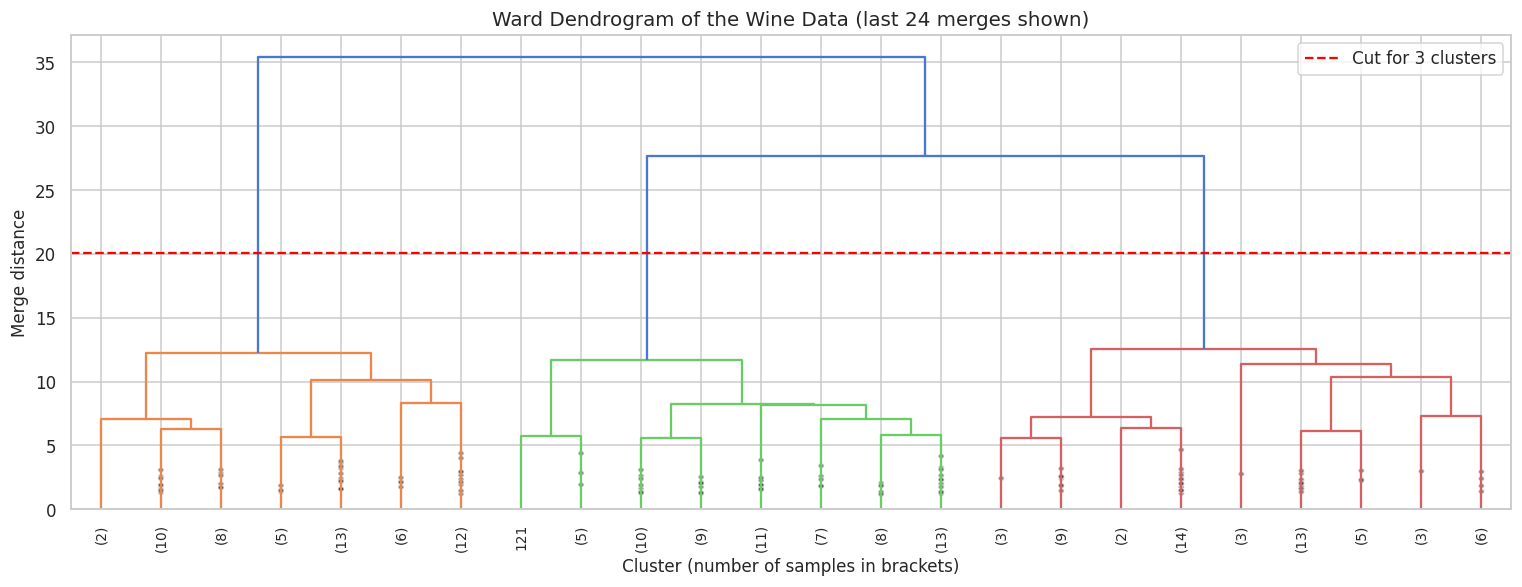

Median merge distance: 2.4.  The last three merges happen at 12.6, 27.7 and 35.4.
Merges far above the typical height join groups that were genuinely distinct: the tree itself hints at a small number of groups.


In [ ]:
# ── 3.1  The dendrogram ──────────────────────────────────────────────
# Height of a merge = how dissimilar the two merged clusters are.
# A long vertical line before a merge means "these clusters were far apart": cut there.

Z = linkage(X_wine_sc, method="ward")

# Cutting between the 2nd-last and 3rd-last merge height yields exactly 3 clusters
cut_height = (Z[-3, 2] + Z[-2, 2]) / 2

fig, ax = plt.subplots(figsize=(14, 5.5))
dendrogram(Z, truncate_mode="lastp", p=24, leaf_rotation=90, leaf_font_size=9,
           show_contracted=True, color_threshold=cut_height, ax=ax)
ax.axhline(cut_height, color="red", linestyle="--", linewidth=1.5, label="Cut for 3 clusters")
ax.set_title("Ward Dendrogram of the Wine Data (last 24 merges shown)")
ax.set_xlabel("Cluster (number of samples in brackets)")
ax.set_ylabel("Merge distance")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Median merge distance: {np.median(Z[:, 2]):.1f}.  The last three merges happen at "
      f"{Z[-3, 2]:.1f}, {Z[-2, 2]:.1f} and {Z[-1, 2]:.1f}.")
print("Merges far above the typical height join groups that were genuinely distinct: the tree itself hints at a small number of groups.")

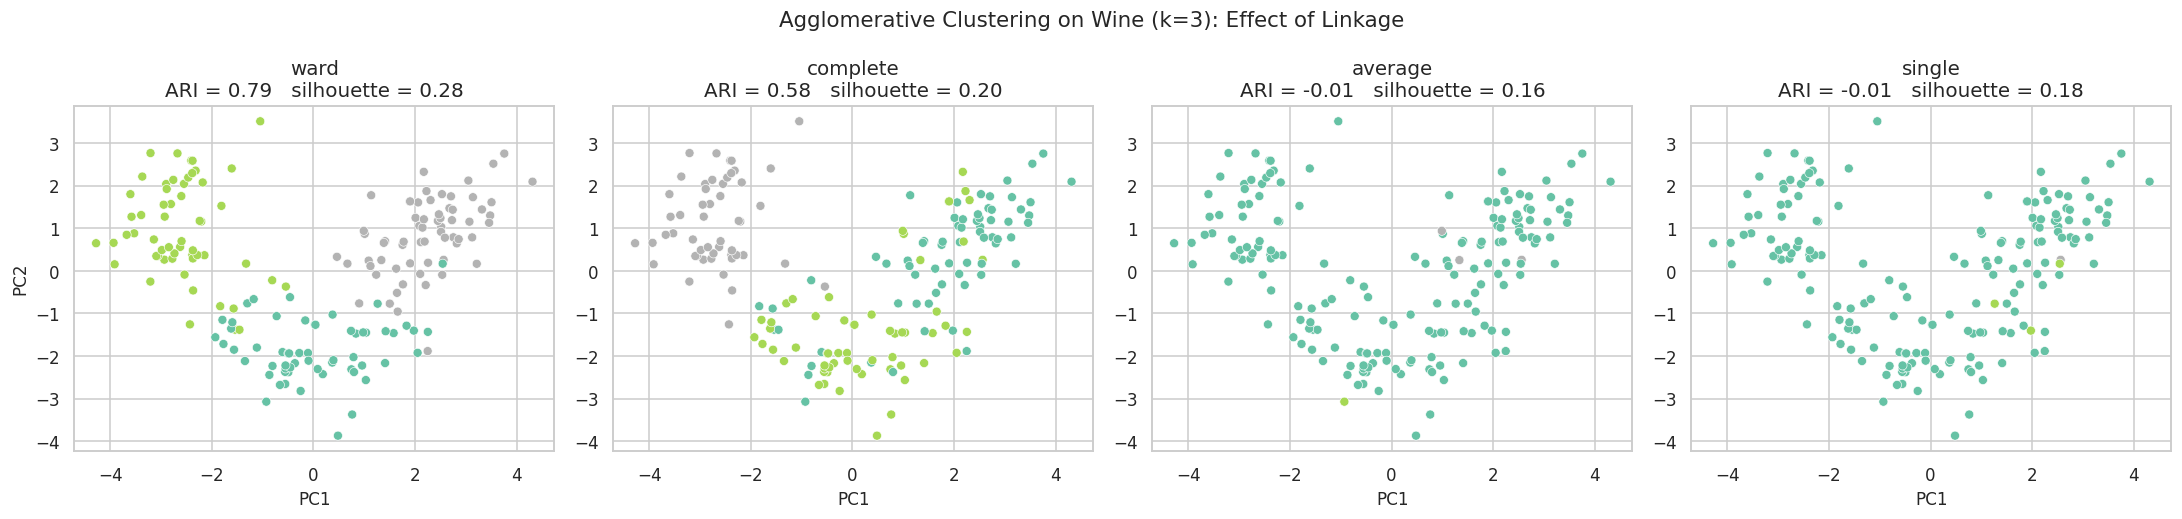

            ARI  silhouette cluster_sizes
linkage                                  
ward      0.790       0.277  [64, 58, 56]
complete  0.577       0.204  [69, 58, 51]
average  -0.005       0.158   [174, 3, 1]
single   -0.007       0.183   [174, 3, 1]

Single and average linkage typically produce one giant cluster plus tiny ones (chaining) on data like this.
Ward is the safest default for compact groups.


In [ ]:
# ── 3.2  Linkage comparison ──────────────────────────────────────────

linkages = ["ward", "complete", "average", "single"]
rows = []

fig, axes = plt.subplots(1, 4, figsize=(20, 4.8))
fig.suptitle("Agglomerative Clustering on Wine (k=3): Effect of Linkage", fontsize=14)

for ax, link in zip(axes, linkages):
    lab = AgglomerativeClustering(n_clusters=3, linkage=link).fit_predict(X_wine_sc)
    ari = adjusted_rand_score(y_wine, lab)
    sil = silhouette_score(X_wine_sc, lab)
    rows.append({"linkage": link, "ARI": ari, "silhouette": sil,
                 "cluster_sizes": sorted(np.bincount(lab).tolist(), reverse=True)})
    ax.scatter(P[:, 0], P[:, 1], c=lab, cmap="Set2", s=35, edgecolors="white", linewidth=0.4)
    ax.set_title(f"{link}\nARI = {ari:.2f}   silhouette = {sil:.2f}")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2" if ax == axes[0] else "")

plt.tight_layout()
plt.show()

print(pd.DataFrame(rows).set_index("linkage").round(3).to_string())
print("\nSingle and average linkage typically produce one giant cluster plus tiny ones (chaining) on data like this.")
print("Ward is the safest default for compact groups.")

### Exercise 2

Using the **Breast Cancer dataset** (scaled):

1. Compute a Ward `linkage` matrix and draw a **truncated dendrogram** (`truncate_mode="lastp"`, `p=30`).
2. Mark the cut that gives **2 clusters** with a horizontal line.
3. Fit `AgglomerativeClustering(n_clusters=2)` for all four linkages. Report **ARI** against `y_bc` and the **cluster sizes** for each.
4. Which linkage works best, and which suffers from chaining? Quote the cluster sizes as evidence.

```python
# Your code here
```

```
# Your answer here
```

---
## Part 4: DBSCAN: Density-Based Clustering

**DBSCAN** defines clusters as **dense regions separated by sparse regions**. It needs no $k$, finds arbitrarily shaped clusters, and labels outliers as **noise** (label `-1`).

Two parameters:

| Parameter | Meaning |
|---|---|
| **`eps`** ($\varepsilon$) | Radius of the neighbourhood around a point |
| **`min_samples`** | Number of points inside that radius for a point to count as a **core point** |

Point types:
- **Core point:** at least `min_samples` neighbours within `eps`.
- **Border point:** within `eps` of a core point but not core itself.
- **Noise point:** neither. These are the outliers.

> **Weak spots:** a single `eps` cannot handle clusters of very different densities, and in high dimensions distances become similar so density is hard to define. Scale features first.

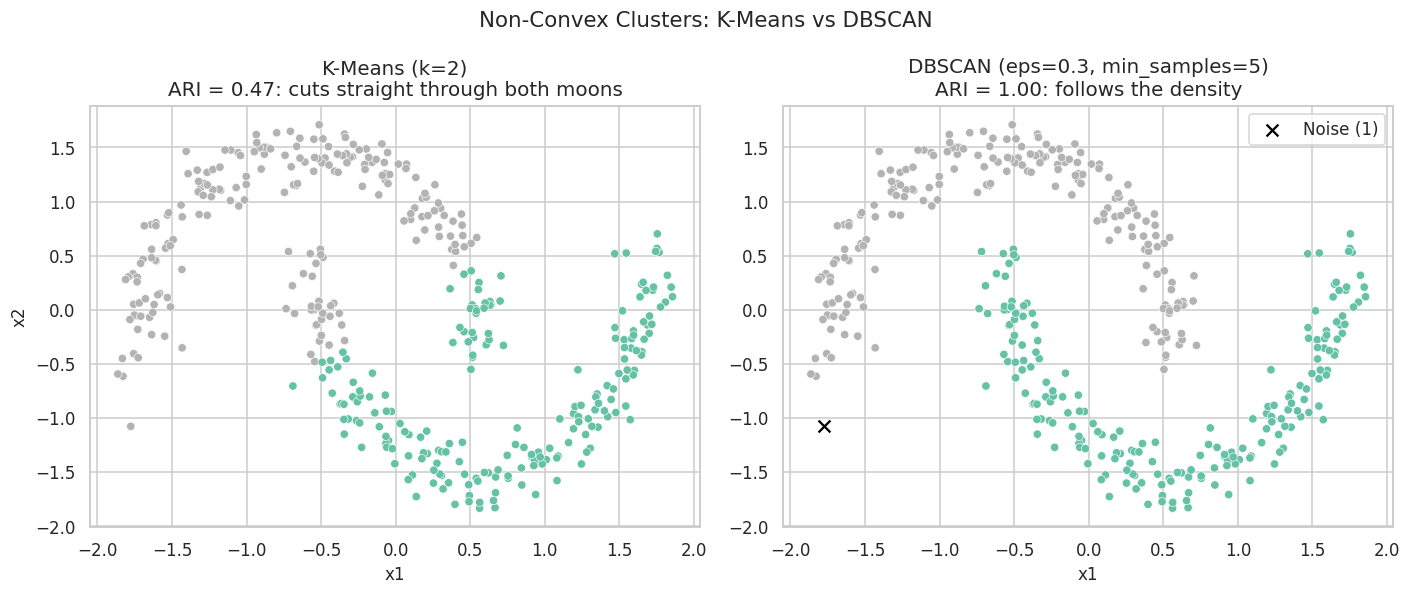

K-Means assumes round clusters around a centre. DBSCAN follows chains of dense points.


In [ ]:
# ── 4.1  Where K-Means fails and DBSCAN succeeds ─────────────────────
# Two interleaving half-moons: a classic non-convex shape.

Xm, ym = make_moons(n_samples=400, noise=0.08, random_state=42)
Xm = StandardScaler().fit_transform(Xm)

km_m = KMeans(n_clusters=2, n_init=10, random_state=42).fit_predict(Xm)
db_m = DBSCAN(eps=0.3, min_samples=5).fit_predict(Xm)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
fig.suptitle("Non-Convex Clusters: K-Means vs DBSCAN", fontsize=14)

axes[0].scatter(Xm[:, 0], Xm[:, 1], c=km_m, cmap="Set2", s=30, edgecolors="white", linewidth=0.4)
axes[0].set_title(f"K-Means (k=2)\nARI = {adjusted_rand_score(ym, km_m):.2f}: cuts straight through both moons")

noise = db_m == -1
axes[1].scatter(Xm[~noise, 0], Xm[~noise, 1], c=db_m[~noise], cmap="Set2", s=30, edgecolors="white", linewidth=0.4)
axes[1].scatter(Xm[noise, 0], Xm[noise, 1], c="black", marker="x", s=60, label=f"Noise ({noise.sum()})")
axes[1].set_title(f"DBSCAN (eps=0.3, min_samples=5)\nARI = {adjusted_rand_score(ym, db_m):.2f}: follows the density")
axes[1].legend()

for ax in axes:
    ax.set_xlabel("x1")
axes[0].set_ylabel("x2")

plt.tight_layout()
plt.show()

print("K-Means assumes round clusters around a centre. DBSCAN follows chains of dense points.")

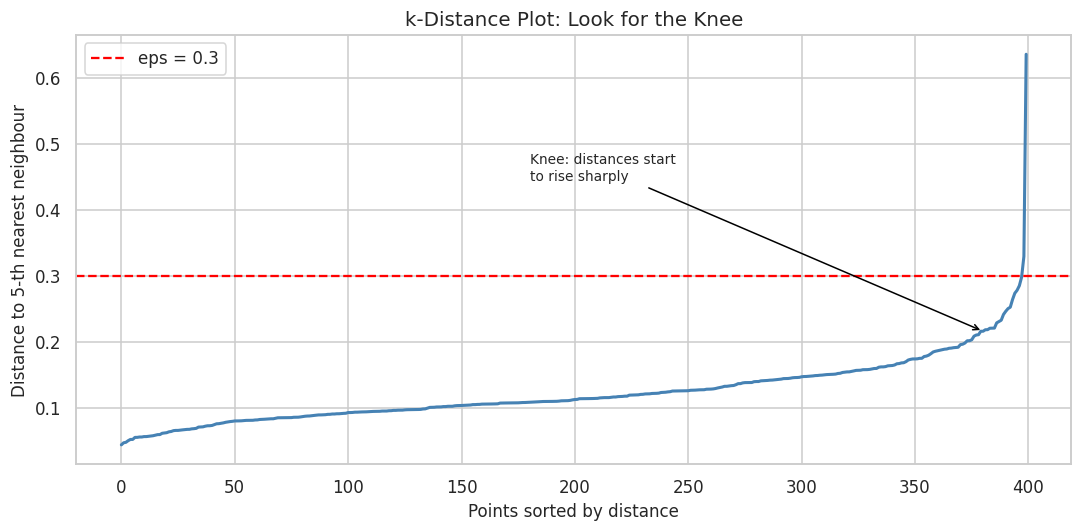

Median 5-NN distance: 0.112   95th percentile: 0.216
A common rule of thumb for min_samples is 2 x n_features (or at least 5). Then pick eps near or just above the knee.


In [ ]:
# ── 4.2  Choosing eps with the k-distance plot ───────────────────────
# For each point compute the distance to its k-th nearest neighbour (k = min_samples),
# sort these distances, and look for the "knee". Below the knee are points inside clusters,
# above it are isolated points. A good eps sits near the knee.

min_samples = 5
nn   = NearestNeighbors(n_neighbors=min_samples).fit(Xm)
dist = np.sort(nn.kneighbors(Xm)[0][:, -1])

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(dist, color="steelblue", linewidth=2)
ax.axhline(0.3, color="red", linestyle="--", linewidth=1.5, label="eps = 0.3")
ax.set_xlabel("Points sorted by distance")
ax.set_ylabel(f"Distance to {min_samples}-th nearest neighbour")
ax.set_title("k-Distance Plot: Look for the Knee")
ax.legend()
ax.annotate("Knee: distances start\nto rise sharply", xy=(len(dist) * 0.95, dist[int(len(dist) * 0.95)]),
            xytext=(len(dist) * 0.45, dist.max() * 0.7), fontsize=9,
            arrowprops=dict(arrowstyle="->", color="black"))
plt.tight_layout()
plt.show()

print(f"Median {min_samples}-NN distance: {np.median(dist):.3f}   95th percentile: {np.percentile(dist, 95):.3f}")
print("A common rule of thumb for min_samples is 2 x n_features (or at least 5). Then pick eps near or just above the knee.")

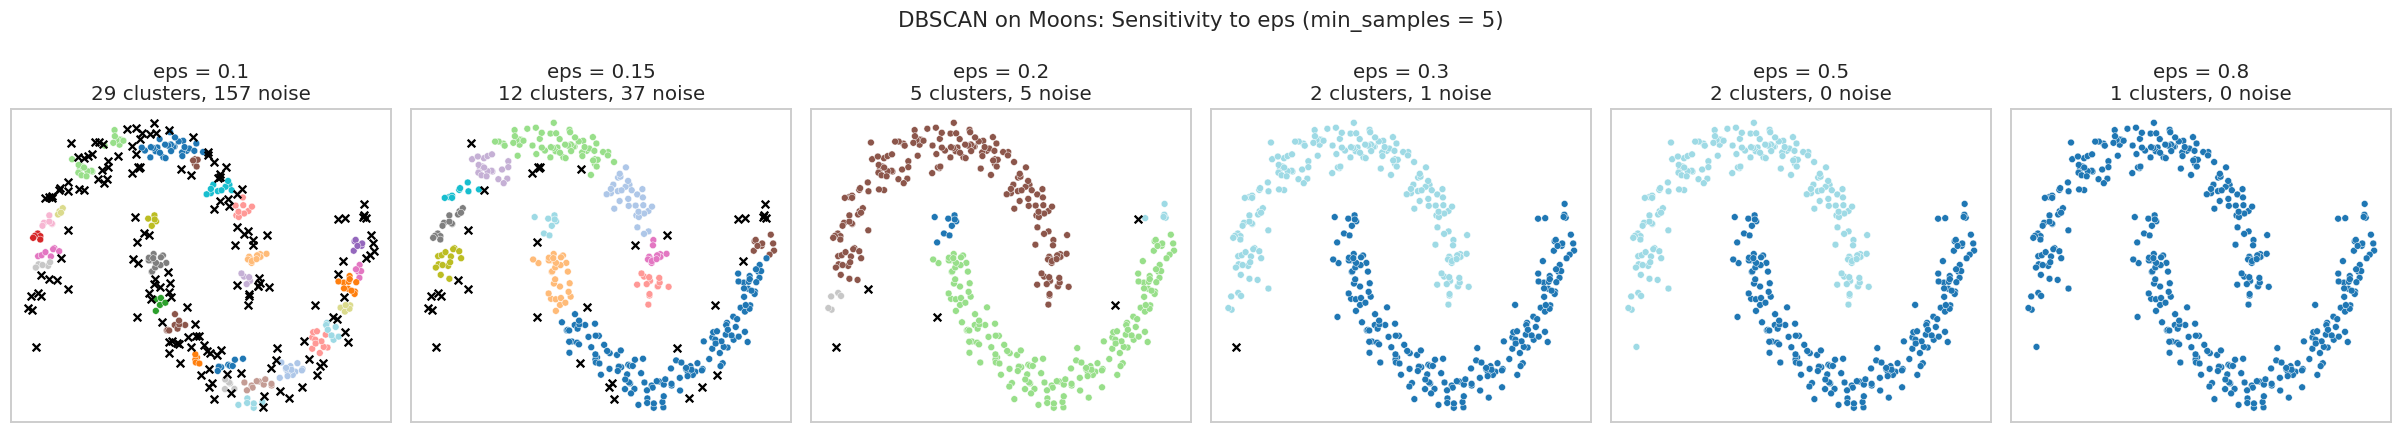

      clusters  noise    ARI
eps                         
0.10        29    157  0.031
0.15        12     37  0.312
0.20         5      5  0.886
0.30         2      1  0.995
0.50         2      0  1.000
0.80         1      0  0.000

Too small: many fragments and lots of noise.  Too large: everything merges into one cluster.


In [ ]:
# ── 4.3  eps sensitivity: too small, just right, too large ───────────

eps_values = [0.10, 0.15, 0.20, 0.30, 0.50, 0.80]

fig, axes = plt.subplots(1, 6, figsize=(22, 4))
fig.suptitle("DBSCAN on Moons: Sensitivity to eps (min_samples = 5)", fontsize=14)

summary = []
for ax, eps in zip(axes, eps_values):
    lab = DBSCAN(eps=eps, min_samples=5).fit_predict(Xm)
    n_clusters = len(set(lab)) - (1 if -1 in lab else 0)
    n_noise    = int((lab == -1).sum())
    summary.append({"eps": eps, "clusters": n_clusters, "noise": n_noise,
                    "ARI": adjusted_rand_score(ym, lab)})
    ok = lab != -1
    ax.scatter(Xm[ok, 0], Xm[ok, 1], c=lab[ok], cmap="tab20", s=20, edgecolors="white", linewidth=0.3)
    ax.scatter(Xm[~ok, 0], Xm[~ok, 1], c="black", marker="x", s=25)
    ax.set_title(f"eps = {eps}\n{n_clusters} clusters, {n_noise} noise")
    ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()

print(pd.DataFrame(summary).set_index("eps").round(3).to_string())
print("\nToo small: many fragments and lots of noise.  Too large: everything merges into one cluster.")

### Exercise 3

Generate concentric circles:

```python
Xc, yc = make_circles(n_samples=500, factor=0.5, noise=0.05, random_state=42)
Xc = StandardScaler().fit_transform(Xc)
```

1. Cluster `Xc` with **K-Means (k=2)**, **Agglomerative with single linkage (k=2)**, and **DBSCAN** (find a good `eps` with a k-distance plot, `min_samples=5`).
2. Plot the three results side by side, and report the **ARI** against `yc` in each title.
3. Which methods recover the two rings, and why does K-Means fail?
4. What happens to DBSCAN if you set `eps=0.5`? Explain in one sentence.

```python
# Your code here
```

```
# Your answer here
```

---
## Part 5: Gaussian Mixture Models: Soft Clustering

A **Gaussian Mixture Model (GMM)** assumes the data come from a mix of $k$ Gaussian distributions, each with its own **mean, covariance (shape and orientation), and weight**. It is fitted with the EM algorithm.

| | K-Means | GMM |
|---|---|---|
| **Assignment** | Hard: each point belongs to exactly one cluster | **Soft**: each point gets a probability for every cluster |
| **Cluster shape** | Spherical (same radius) | **Ellipses** of different size and orientation |
| **Choosing k** | Elbow / silhouette | Elbow / silhouette **and BIC** (a likelihood with a penalty for complexity; lower is better) |

> K-Means is a special case of GMM with equal, spherical clusters. Use GMM when clusters are elongated or overlap, or when you need **uncertainty** about each assignment.

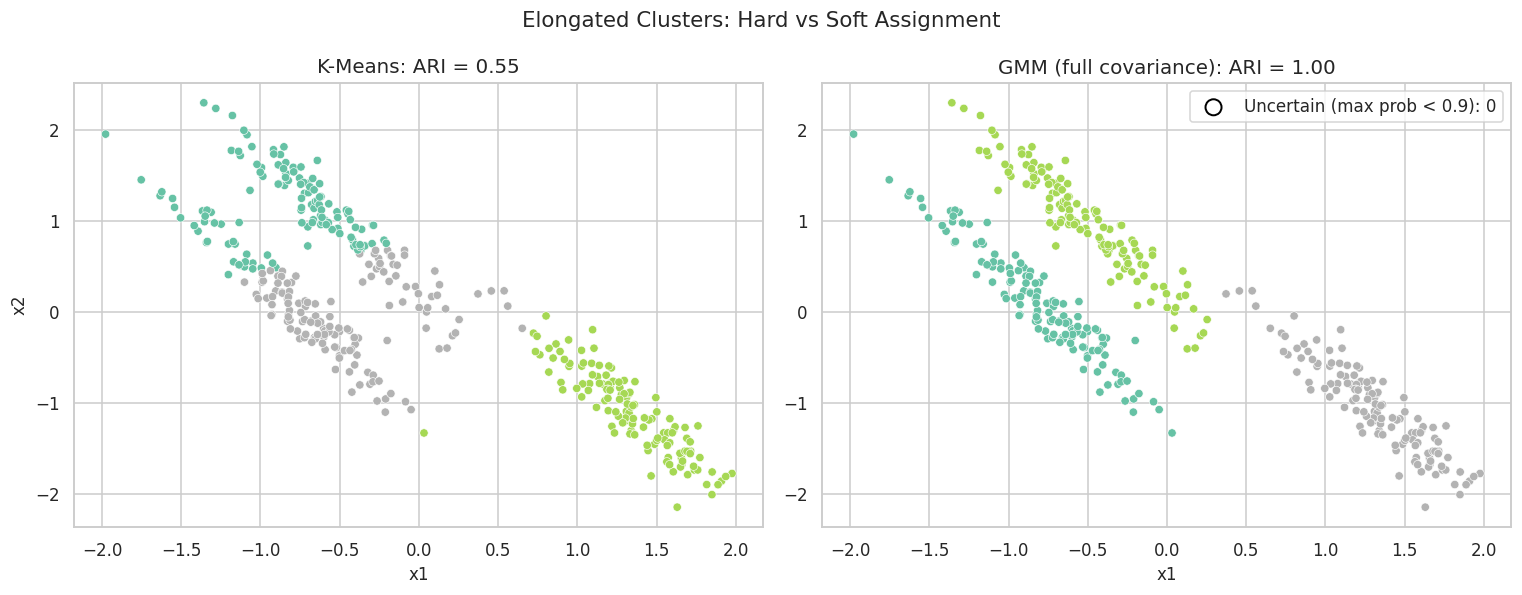

GMM learns the tilted ellipses. The circled points sit where clusters overlap: GMM knows it is unsure,
K-Means would have given them a confident hard label anyway.


In [ ]:
# ── 5.1  Elongated clusters: K-Means vs GMM ──────────────────────────
# We stretch and rotate three blobs so they become tilted ellipses.

Xa, ya = make_blobs(n_samples=400, centers=3, random_state=170)
Xa = Xa @ np.array([[0.6, -0.64], [-0.4, 0.85]])
Xa = StandardScaler().fit_transform(Xa)

km_a  = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(Xa)
gmm_a = GaussianMixture(n_components=3, covariance_type="full", random_state=42).fit(Xa)
lab_g = gmm_a.predict(Xa)
conf  = gmm_a.predict_proba(Xa).max(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
fig.suptitle("Elongated Clusters: Hard vs Soft Assignment", fontsize=14)

axes[0].scatter(Xa[:, 0], Xa[:, 1], c=km_a, cmap="Set2", s=30, edgecolors="white", linewidth=0.4)
axes[0].set_title(f"K-Means: ARI = {adjusted_rand_score(ya, km_a):.2f}")

axes[1].scatter(Xa[:, 0], Xa[:, 1], c=lab_g, cmap="Set2", s=30, edgecolors="white", linewidth=0.4)
unsure = conf < 0.9
axes[1].scatter(Xa[unsure, 0], Xa[unsure, 1], facecolors="none", edgecolors="black", s=110, linewidth=1.3,
                label=f"Uncertain (max prob < 0.9): {unsure.sum()}")
axes[1].set_title(f"GMM (full covariance): ARI = {adjusted_rand_score(ya, lab_g):.2f}")
axes[1].legend(loc="upper right")

for ax in axes:
    ax.set_xlabel("x1")
axes[0].set_ylabel("x2")

plt.tight_layout()
plt.show()

print("GMM learns the tilted ellipses. The circled points sit where clusters overlap: GMM knows it is unsure,")
print("K-Means would have given them a confident hard label anyway.")

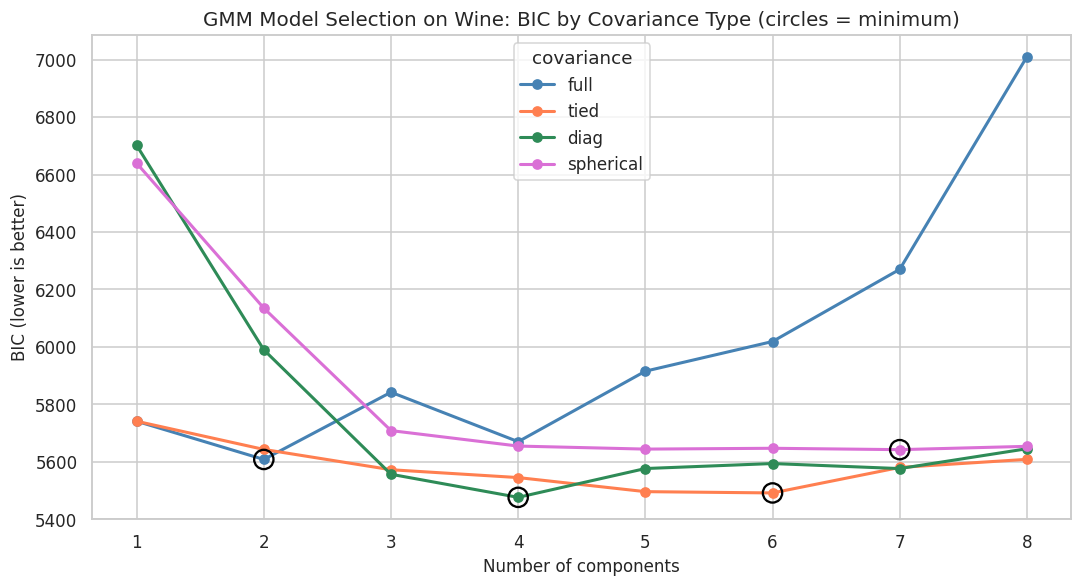

Lowest BIC overall: covariance = 'diag', components = 4
BIC does not have to agree with the 'true' 3 cultivars: it measures density-model fit, not what a human
meant by a group. Treat BIC, silhouette, stability and domain knowledge as evidence, not as an oracle.


In [ ]:
# ── 5.2  Choosing k and covariance type with BIC (wine) ──────────────
# BIC = -2 log-likelihood + (number of parameters) x log(n). Lower is better.
# More flexible covariance types need more parameters, so BIC penalises them.

cov_types = ["full", "tied", "diag", "spherical"]
ns = range(1, 9)
bic = {ct: [GaussianMixture(n, covariance_type=ct, n_init=3, random_state=0).fit(X_wine_sc).bic(X_wine_sc)
            for n in ns] for ct in cov_types}

fig, ax = plt.subplots(figsize=(10, 5.5))
for ct, color in zip(cov_types, ["steelblue", "coral", "seagreen", "orchid"]):
    ax.plot(list(ns), bic[ct], "o-", color=color, linewidth=2, label=ct)
    best_n = list(ns)[int(np.argmin(bic[ct]))]
    ax.scatter([best_n], [min(bic[ct])], s=160, facecolors="none", edgecolors="black", linewidth=1.5, zorder=5)
ax.set_xlabel("Number of components")
ax.set_ylabel("BIC (lower is better)")
ax.set_title("GMM Model Selection on Wine: BIC by Covariance Type (circles = minimum)")
ax.legend(title="covariance")
plt.tight_layout()
plt.show()

best_ct = min(cov_types, key=lambda c: min(bic[c]))
best_nn = list(ns)[int(np.argmin(bic[best_ct]))]
print(f"Lowest BIC overall: covariance = '{best_ct}', components = {best_nn}")
print("BIC does not have to agree with the 'true' 3 cultivars: it measures density-model fit, not what a human")
print("meant by a group. Treat BIC, silhouette, stability and domain knowledge as evidence, not as an oracle.")

---
## Part 6: Algorithm Showdown and Evaluating Clusters

No algorithm wins everywhere. The shape of the clusters decides.

| Cluster shape | K-Means | Ward | DBSCAN | GMM |
|---|---|---|---|---|
| **Round, similar size** | Good | Good | Good | Good |
| **Elongated / tilted** | Poor | Poor | Depends on eps | **Good** |
| **Non-convex (moons, rings)** | Poor | Poor | **Good** | Poor |
| **Outliers present** | Distorted | Distorted | **Flags them as noise** | Distorted |

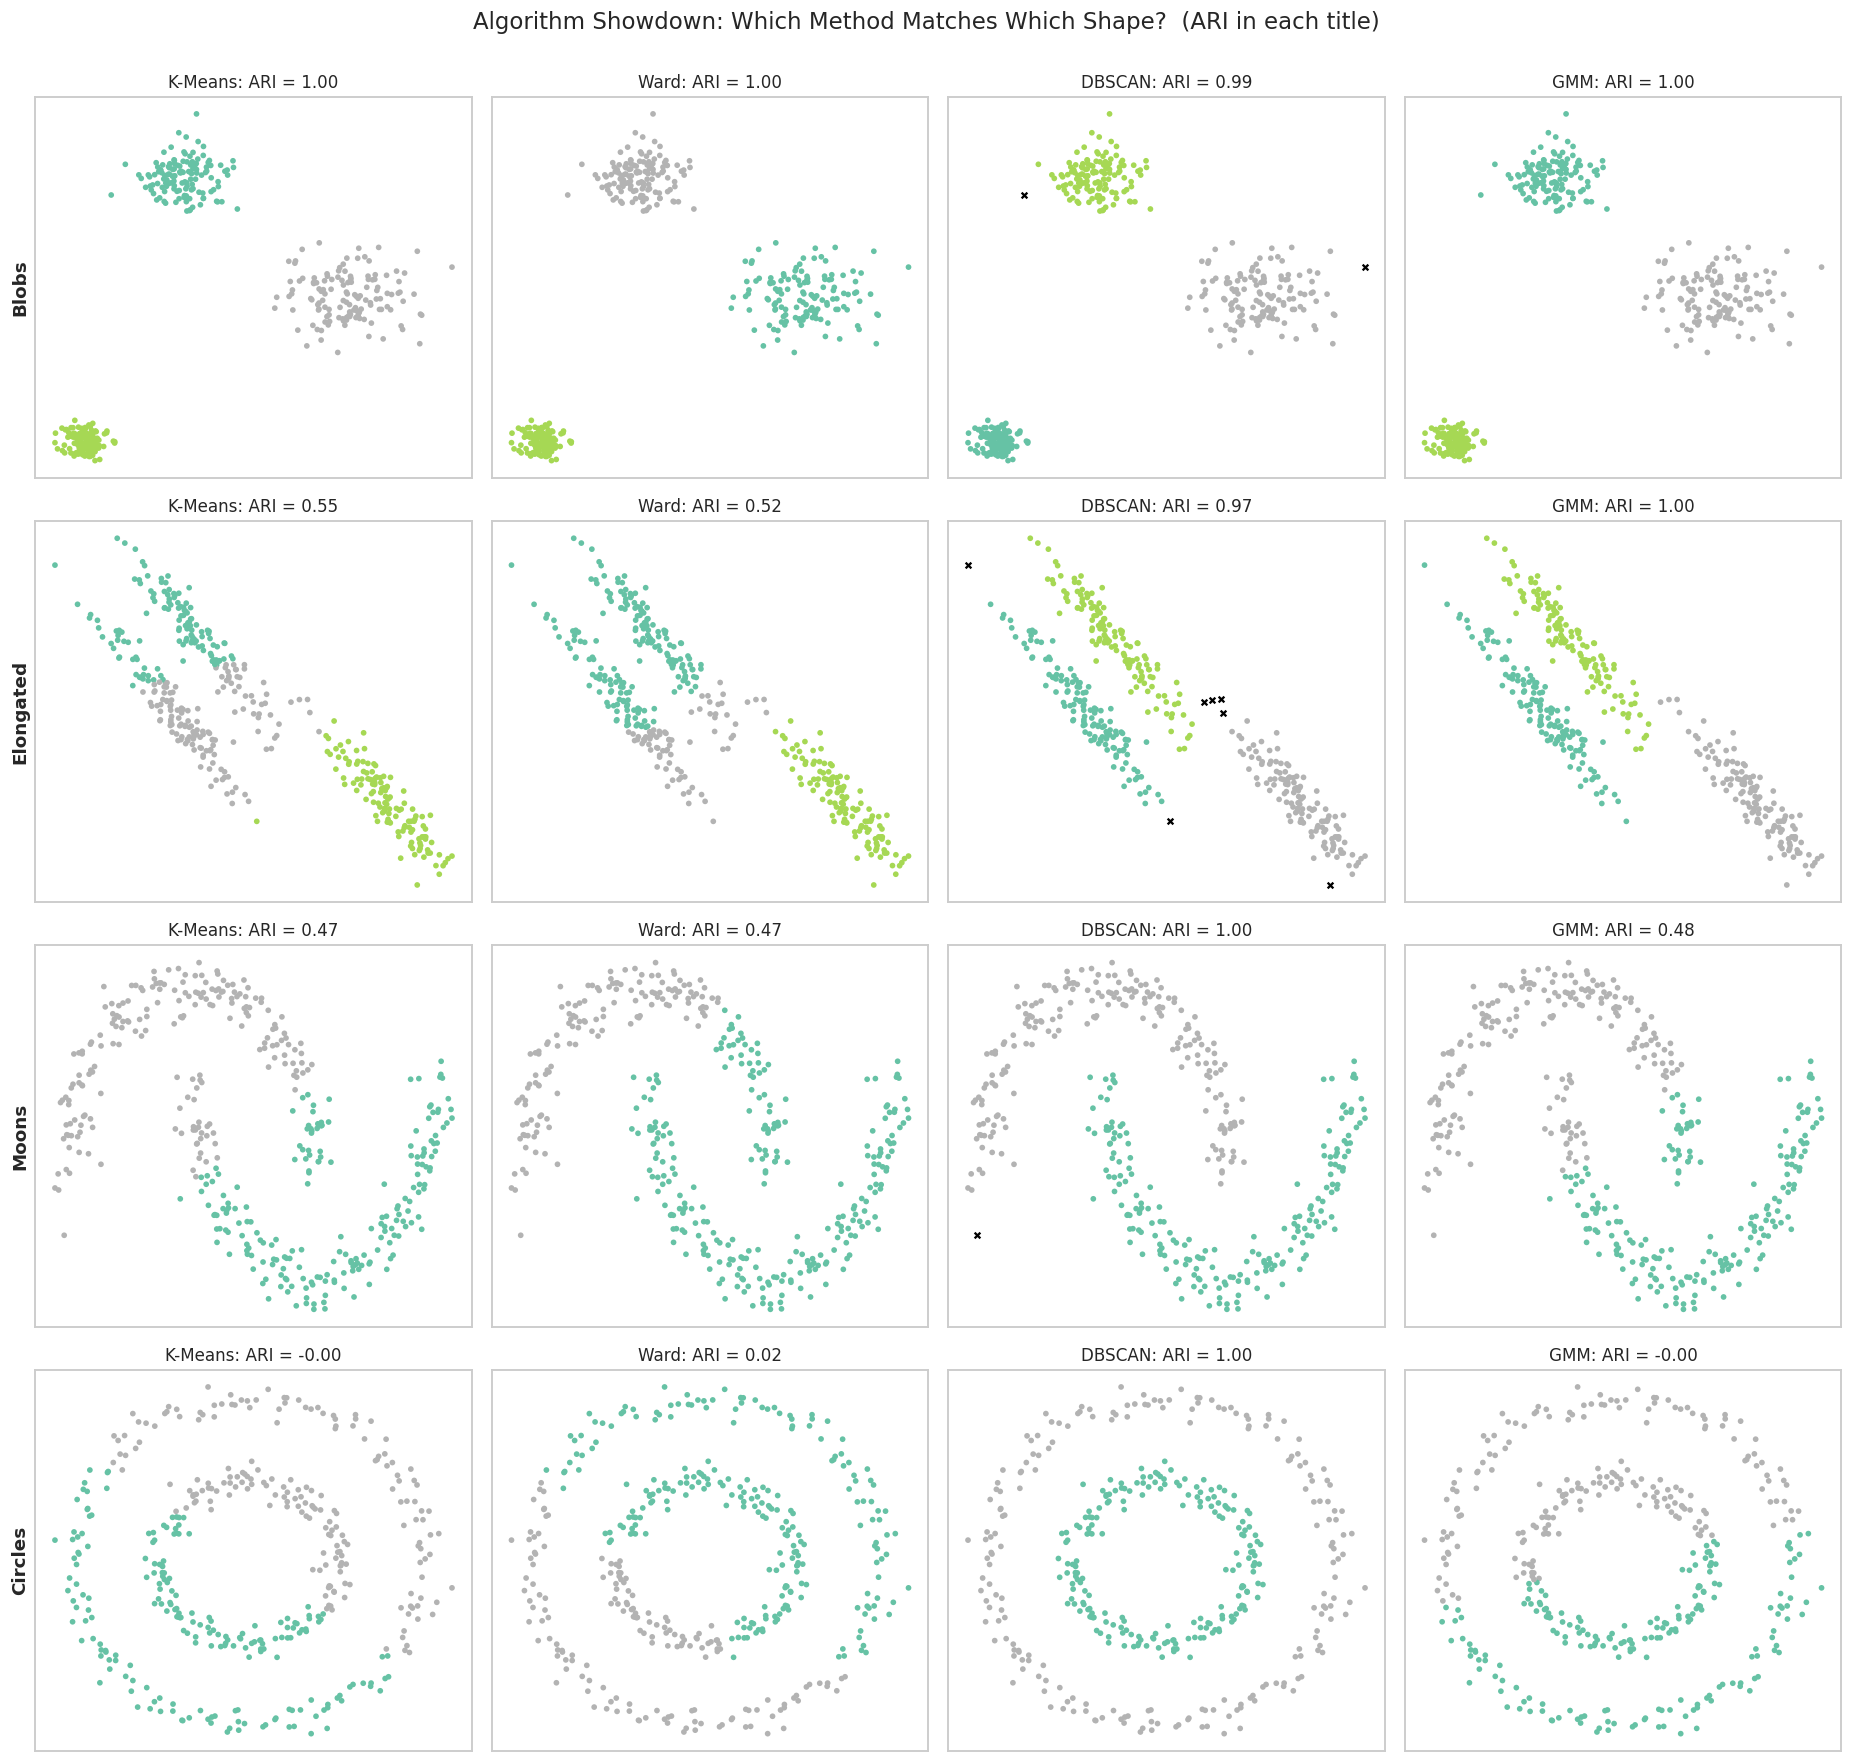

           K-Means  Ward  DBSCAN   GMM
Blobs         1.00  1.00    0.99  1.00
Elongated     0.55  0.52    0.97  1.00
Moons         0.47  0.47    1.00  0.48
Circles      -0.00  0.02    1.00 -0.00

Read down the columns: no single algorithm is best on every shape.


In [ ]:
# ── 6.1  Four algorithms x four dataset shapes ───────────────────────

n = 400
Xb_, yb_ = make_blobs(n, centers=3, cluster_std=[1.0, 1.5, 0.5], random_state=42)
Xa_, ya_ = make_blobs(n, centers=3, random_state=170)
Xa_ = Xa_ @ np.array([[0.6, -0.64], [-0.4, 0.85]])
Xm_, ym_ = make_moons(n, noise=0.08, random_state=42)
Xc_, yc_ = make_circles(n, noise=0.05, factor=0.5, random_state=42)

shapes = {
    "Blobs":      (StandardScaler().fit_transform(Xb_), yb_, 3, 0.30),
    "Elongated":  (StandardScaler().fit_transform(Xa_), ya_, 3, 0.25),
    "Moons":      (StandardScaler().fit_transform(Xm_), ym_, 2, 0.30),
    "Circles":    (StandardScaler().fit_transform(Xc_), yc_, 2, 0.30),
}

fig, axes = plt.subplots(4, 4, figsize=(17, 16))
fig.suptitle("Algorithm Showdown: Which Method Matches Which Shape?  (ARI in each title)", fontsize=15, y=1.0)

ari_table = {}
for r, (name, (X, y, k, eps)) in enumerate(shapes.items()):
    algos = {
        "K-Means":        KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X),
        "Ward":           AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X),
        "DBSCAN":         DBSCAN(eps=eps, min_samples=5).fit_predict(X),
        "GMM":            GaussianMixture(n_components=k, covariance_type="full", random_state=42).fit_predict(X),
    }
    for c, (aname, lab) in enumerate(algos.items()):
        ax = axes[r, c]
        ok = lab != -1
        ax.scatter(X[ok, 0], X[ok, 1], c=lab[ok], cmap="Set2", s=14, edgecolors="none")
        ax.scatter(X[~ok, 0], X[~ok, 1], c="black", marker="x", s=14)
        ari = adjusted_rand_score(y, lab)
        ari_table.setdefault(name, {})[aname] = ari
        ax.set_title(f"{aname}: ARI = {ari:.2f}", fontsize=11)
        ax.set_xticks([]); ax.set_yticks([])
        if c == 0:
            ax.set_ylabel(name, fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()

print(pd.DataFrame(ari_table).T.round(2).to_string())
print("\nRead down the columns: no single algorithm is best on every shape.")

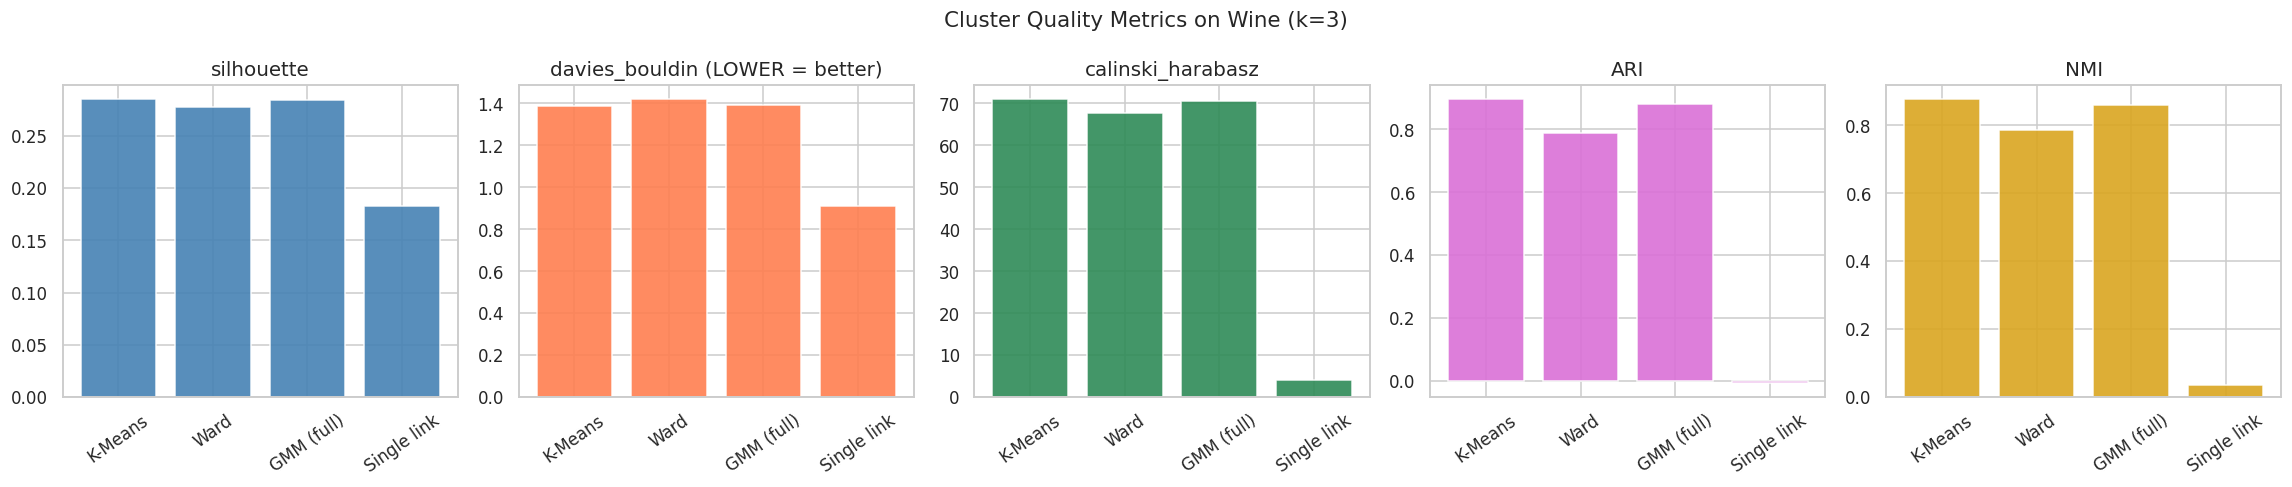

             silhouette  davies_bouldin  calinski_harabasz    ARI    NMI
algorithm                                                               
K-Means           0.285           1.389             70.940  0.897  0.876
Ward              0.277           1.419             67.647  0.790  0.786
GMM (full)        0.284           1.394             70.688  0.880  0.861
Single link       0.183           0.911              4.062 -0.007  0.035

Caution: Davies-Bouldin (lower = better) rates single linkage as the BEST, while ARI and NMI rate it the worst.
Single linkage made one giant cluster plus two tiny ones, which fools the index. Always inspect cluster sizes too.


In [ ]:
# ── 6.2  Internal vs external metrics on the wine data ───────────────
# INTERNAL metrics need only the data and the labels the algorithm found.
#   silhouette         higher is better (-1 to 1)
#   Davies-Bouldin     LOWER is better  (average similarity of each cluster to its closest other cluster)
#   Calinski-Harabasz  higher is better (between-cluster vs within-cluster dispersion)
# EXTERNAL metrics compare with a known grouping, so they are only available in a teaching setting.
#   ARI, NMI           higher is better (1 = perfect agreement)

wine_algos = {
    "K-Means":     KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(X_wine_sc),
    "Ward":        AgglomerativeClustering(n_clusters=3, linkage="ward").fit_predict(X_wine_sc),
    "GMM (full)":  GaussianMixture(n_components=3, covariance_type="full", n_init=3, random_state=42).fit_predict(X_wine_sc),
    "Single link": AgglomerativeClustering(n_clusters=3, linkage="single").fit_predict(X_wine_sc),
}

rows = []
for name, lab in wine_algos.items():
    rows.append({"algorithm": name,
                 "silhouette":        silhouette_score(X_wine_sc, lab),
                 "davies_bouldin":    davies_bouldin_score(X_wine_sc, lab),
                 "calinski_harabasz": calinski_harabasz_score(X_wine_sc, lab),
                 "ARI":               adjusted_rand_score(y_wine, lab),
                 "NMI":               normalized_mutual_info_score(y_wine, lab)})
met = pd.DataFrame(rows).set_index("algorithm")

fig, axes = plt.subplots(1, 5, figsize=(21, 4.5))
fig.suptitle("Cluster Quality Metrics on Wine (k=3)", fontsize=14)
for ax, col, color in zip(axes, met.columns, ["steelblue", "coral", "seagreen", "orchid", "goldenrod"]):
    ax.bar(met.index, met[col], color=color, edgecolor="white", alpha=0.9)
    ax.set_title(col + (" (LOWER = better)" if col == "davies_bouldin" else ""))
    ax.tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

print(met.round(3).to_string())
print("\nCaution: Davies-Bouldin (lower = better) rates single linkage as the BEST, while ARI and NMI rate it the worst.")
print("Single linkage made one giant cluster plus two tiny ones, which fools the index. Always inspect cluster sizes too.")

In [ ]:
# ── 6.3  The internal-metric trap ────────────────────────────────────
# Internal metrics like silhouette reward compact, well-separated blobs.
# On non-convex data they can prefer the WRONG answer.

lab_km = KMeans(n_clusters=2, n_init=10, random_state=42).fit_predict(Xm)
lab_db = DBSCAN(eps=0.3, min_samples=5).fit_predict(Xm)
ok = lab_db != -1

trap = pd.DataFrame({
    "silhouette": [silhouette_score(Xm, lab_km), silhouette_score(Xm[ok], lab_db[ok])],
    "ARI vs truth": [adjusted_rand_score(ym, lab_km), adjusted_rand_score(ym, lab_db)],
}, index=["K-Means (wrong shape)", "DBSCAN (right shape)"])

print(trap.round(3).to_string())
print("\nK-Means has the higher silhouette, yet DBSCAN is the one that recovered the real structure.")
print("Lesson: when there are no labels, never rely on one internal metric. Look at the clusters.")

                       silhouette  ARI vs truth
K-Means (wrong shape)       0.491         0.475
DBSCAN (right shape)        0.376         0.995

K-Means has the higher silhouette, yet DBSCAN is the one that recovered the real structure.
Lesson: when there are no labels, never rely on one internal metric. Look at the clusters.


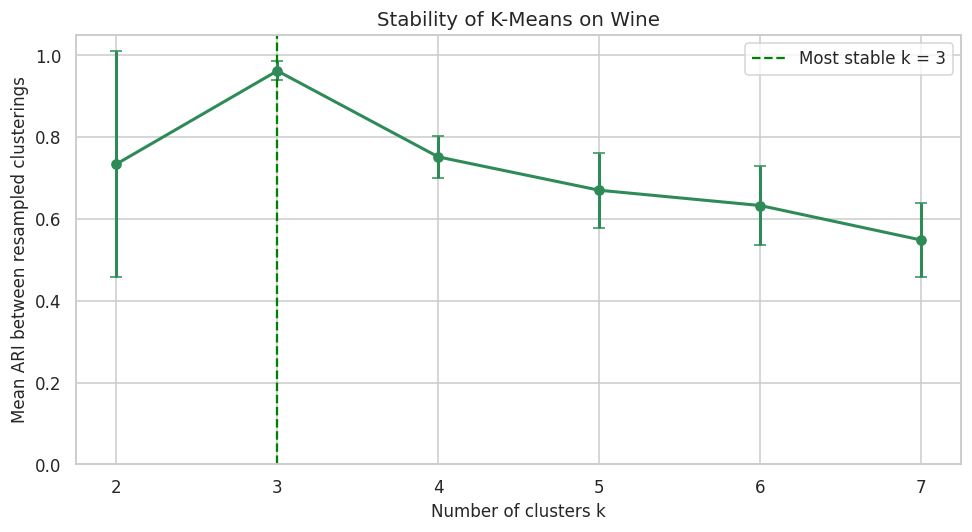

Most stable k: 3  (mean ARI = 0.962)
Silhouette, BIC, stability and domain knowledge together make a far stronger case than any one of them.


In [ ]:
# ── 6.4  Stability: do the clusters survive resampling? ──────────────
# Without labels, a useful sanity check is stability: cluster two random 80% subsamples,
# label ALL points with each fitted model, and measure agreement (ARI). Real structure is reproducible.

rs = np.random.default_rng(0)
X_arr = X_wine_sc.values
stab = {}
for k in range(2, 8):
    scores = []
    for t in range(15):
        i1 = rs.choice(len(X_arr), int(0.8 * len(X_arr)), replace=False)
        i2 = rs.choice(len(X_arr), int(0.8 * len(X_arr)), replace=False)
        m1 = KMeans(n_clusters=k, n_init=5, random_state=t).fit(X_arr[i1])
        m2 = KMeans(n_clusters=k, n_init=5, random_state=t + 100).fit(X_arr[i2])
        scores.append(adjusted_rand_score(m1.predict(X_arr), m2.predict(X_arr)))
    stab[k] = (np.mean(scores), np.std(scores))

ks_ = list(stab)
fig, ax = plt.subplots(figsize=(9, 5))
ax.errorbar(ks_, [stab[k][0] for k in ks_], yerr=[stab[k][1] for k in ks_],
            fmt="o-", color="seagreen", linewidth=2, capsize=4)
best_stab = ks_[int(np.argmax([stab[k][0] for k in ks_]))]
ax.axvline(best_stab, color="green", linestyle="--", label=f"Most stable k = {best_stab}")
ax.set_xlabel("Number of clusters k")
ax.set_ylabel("Mean ARI between resampled clusterings")
ax.set_title("Stability of K-Means on Wine")
ax.set_ylim(0, 1.05)
ax.legend()
plt.tight_layout()
plt.show()

print(f"Most stable k: {best_stab}  (mean ARI = {stab[best_stab][0]:.3f})")
print("Silhouette, BIC, stability and domain knowledge together make a far stronger case than any one of them.")

### Exercise 4

Using the **Breast Cancer dataset** (scaled):

1. Fit **K-Means (k=2)**, **Ward (k=2)**, and **GMM (2 components, full covariance)**.
2. Build a table with **silhouette, Davies-Bouldin, Calinski-Harabasz, ARI, and NMI** for each algorithm.
3. Plot the five metrics as five small bar charts in one row.
4. Which algorithm looks best by the **internal** metrics? Which by the **external** metrics? Do they agree?
5. Write one sentence on why a high silhouette alone would not prove the clusters are meaningful.

```python
# Your code here
```

```
# Your answer here
```

---
## Part 7: From Clusters to Insight: Pipelines, Profiles & Storytelling

Clusters are only useful when you can **describe** them. The standard recipe:

1. **Scale** the features.
2. Optionally **reduce dimension** (PCA) to remove noise and speed up distance computations.
3. **Cluster.**
4. **Profile** each cluster: compare the mean of every feature per cluster with the overall mean. Features far from average define the cluster's identity.
5. **Name** the clusters and present them.

> Profiling is done on **standardised** values (z-scores) so that "+1.2" always means "1.2 standard deviations above average", regardless of units.

In [ ]:
# ── 7.1  A clustering pipeline: Scale -> PCA -> K-Means ──────────────

pipe = Pipeline([
    ("scaler",  StandardScaler()),
    ("pca",     PCA(n_components=0.90, random_state=42)),     # keep 90% of the variance
    ("cluster", KMeans(n_clusters=3, n_init=10, random_state=42)),
])
lab_pipe = pipe.fit_predict(X_wine)

print(f"PCA kept {pipe.named_steps['pca'].n_components_} of {X_wine.shape[1]} components (90% of variance)")
print(f"Pipeline ARI vs truth:        {adjusted_rand_score(y_wine, lab_pipe):.3f}")
print(f"Plain scaled K-Means ARI:     {adjusted_rand_score(y_wine, km_scaled.labels_):.3f}")
print("\nThe pipeline is a single object: it applies scaling and PCA, then clusters. Fit it on the data you want to")
print("cluster, and later call .predict() on new samples to assign them to the existing clusters.")

PCA kept 8 of 13 components (90% of variance)
Pipeline ARI vs truth:        0.897
Plain scaled K-Means ARI:     0.897

The pipeline is a single object: it applies scaling and PCA, then clusters. Fit it on the data you want to
cluster, and later call .predict() on new samples to assign them to the existing clusters.


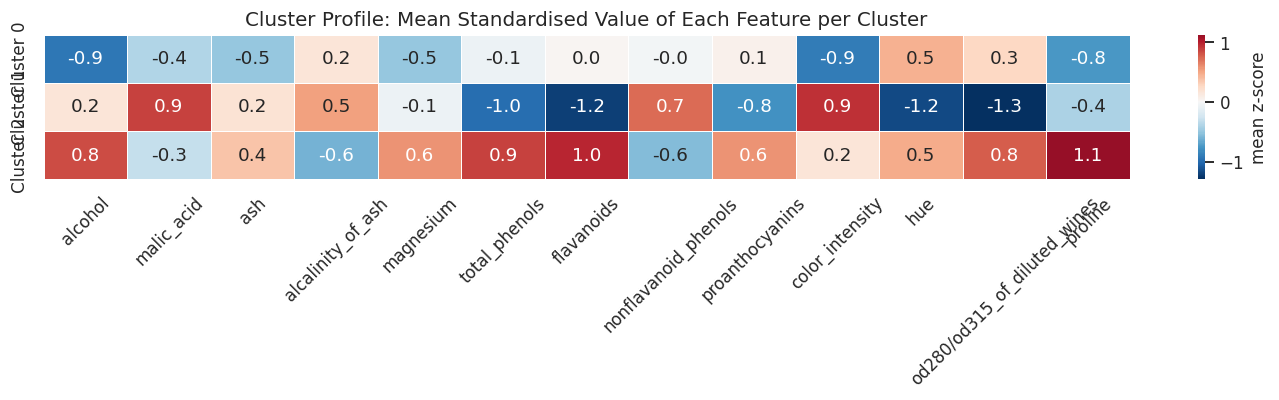

Cluster 0: HIGH in ['hue (+0.5)', 'od280/od315_of_diluted_wines (+0.3)', 'alcalinity_of_ash (+0.2)']
           LOW  in ['alcohol (-0.9)', 'color_intensity (-0.9)', 'proline (-0.8)']
Cluster 1: HIGH in ['color_intensity (+0.9)', 'malic_acid (+0.9)', 'nonflavanoid_phenols (+0.7)']
           LOW  in ['od280/od315_of_diluted_wines (-1.3)', 'flavanoids (-1.2)', 'hue (-1.2)']
Cluster 2: HIGH in ['proline (+1.1)', 'flavanoids (+1.0)', 'total_phenols (+0.9)']
           LOW  in ['alcalinity_of_ash (-0.6)', 'nonflavanoid_phenols (-0.6)', 'malic_acid (-0.3)']


In [ ]:
# ── 7.2  Cluster profiling: what makes each cluster different? ───────

profile = X_wine_sc.groupby(km_scaled.labels_).mean()
profile.index = [f"Cluster {i}" for i in profile.index]

fig, ax = plt.subplots(figsize=(13, 3.8))
sns.heatmap(profile, annot=True, fmt=".1f", cmap="RdBu_r", center=0, linewidths=0.5,
            ax=ax, cbar_kws={"label": "mean z-score"})
ax.set_title("Cluster Profile: Mean Standardised Value of Each Feature per Cluster")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

for c in profile.index:
    hi = profile.loc[c].nlargest(3)
    lo = profile.loc[c].nsmallest(3)
    print(f"{c}: HIGH in {[f'{f} ({v:+.1f})' for f, v in hi.items()]}")
    print(f"{' ' * len(c)}  LOW  in {[f'{f} ({v:+.1f})' for f, v in lo.items()]}")

### The clustering storytelling dashboard

**Storytelling checklist:**
1. **How many clusters?** Evidence from elbow and silhouette.
2. **What do they look like?** A 2D projection of the clusters.
3. **What defines them?** The cluster profile.
4. **Do they mean anything?** Cross-check against a known grouping if one exists.

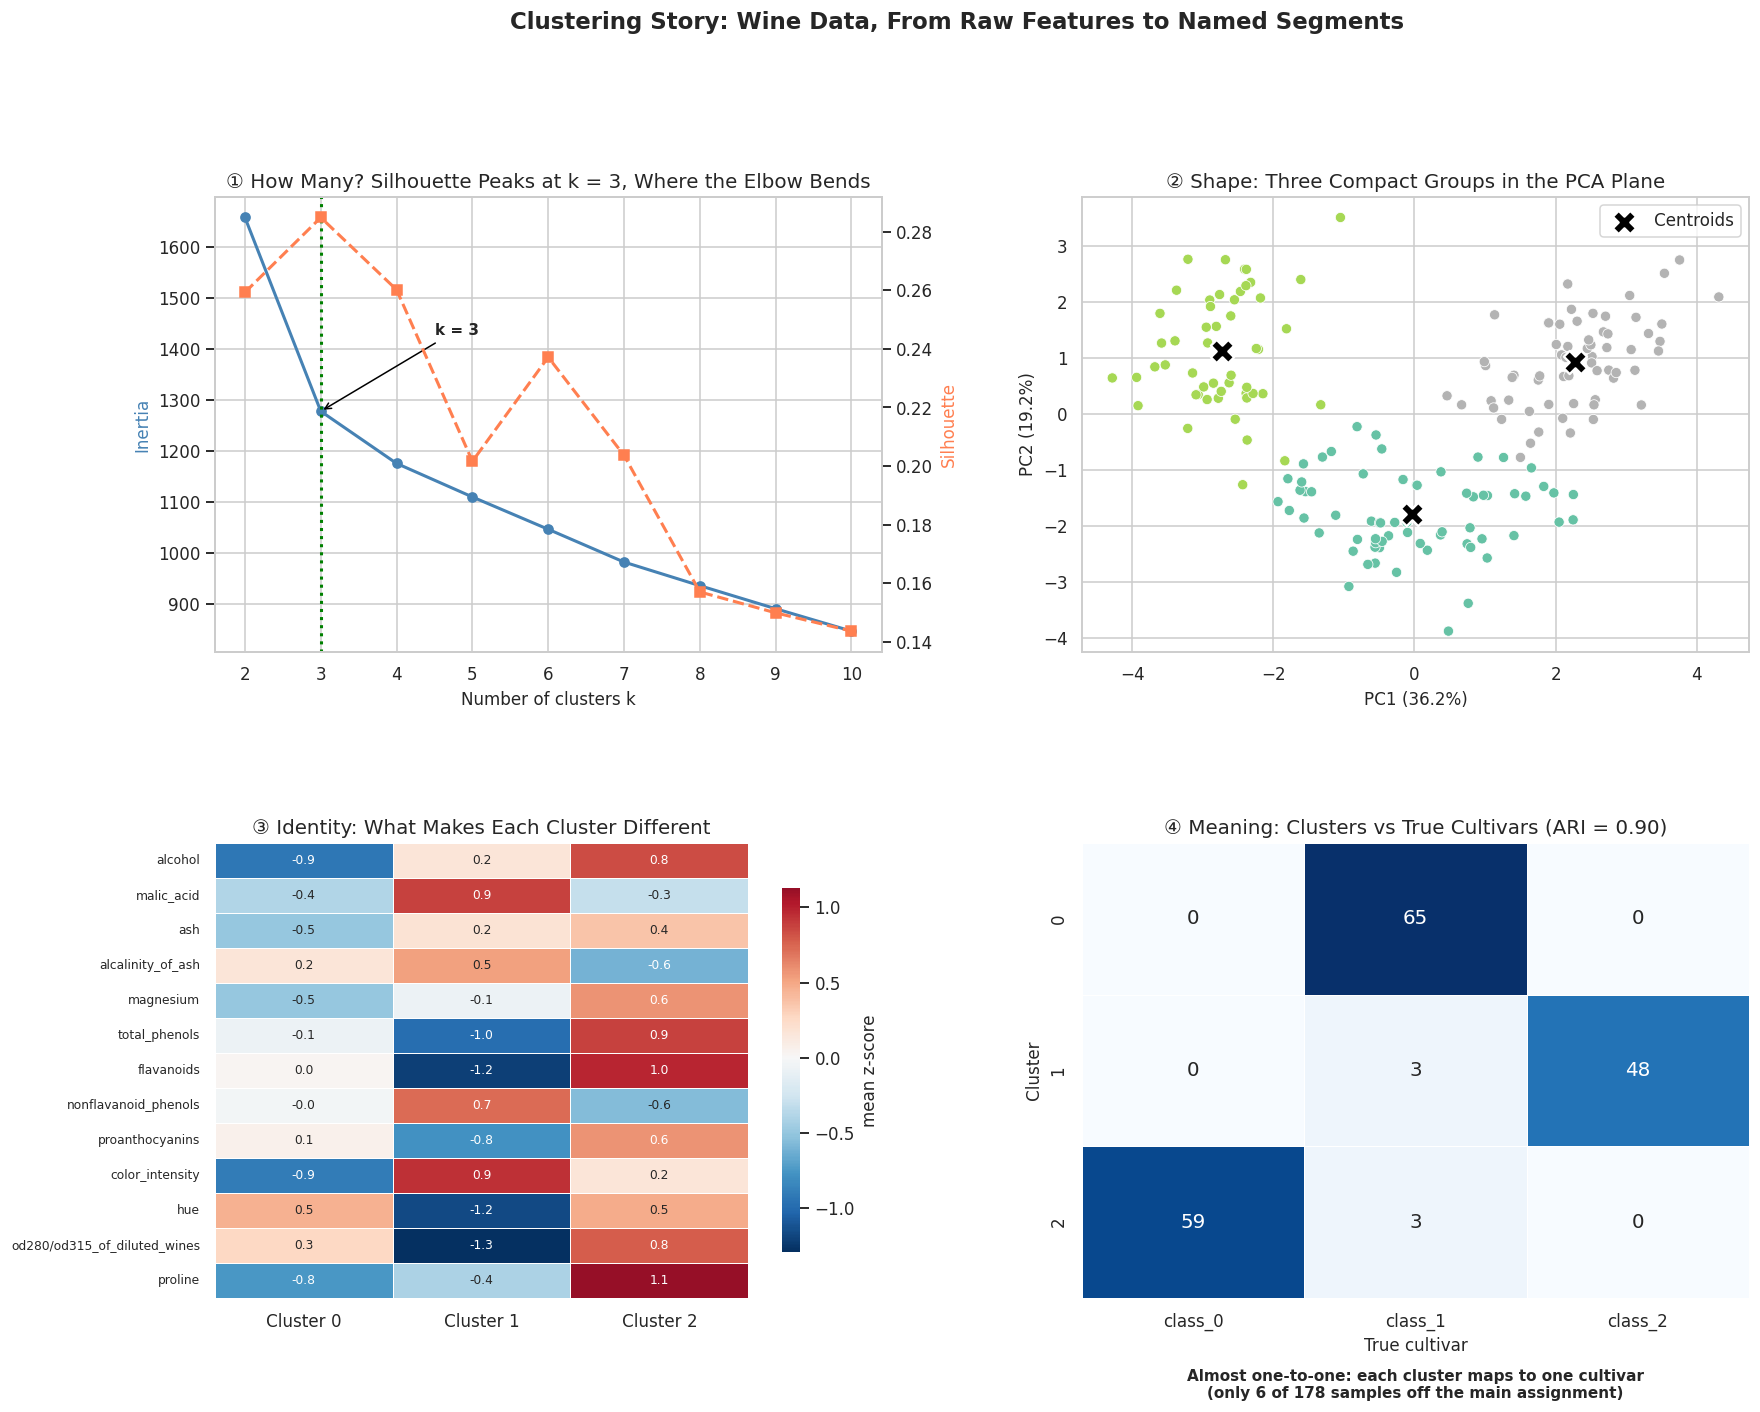

Dashboard saved as clustering_dashboard.png


In [ ]:
# ── 7.3  The Clustering Dashboard ────────────────────────────────────

fig = plt.figure(figsize=(18, 13))
fig.suptitle("Clustering Story: Wine Data, From Raw Features to Named Segments",
             fontsize=15, fontweight="bold", y=1.01)

gs = gridspec.GridSpec(2, 2, hspace=0.42, wspace=0.30)

# ── Panel 1: how many clusters? ───────────────────────────────────────
ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(list(ks), inertias, "o-", color="steelblue", linewidth=2, label="Inertia")
ax1.set_xlabel("Number of clusters k")
ax1.set_ylabel("Inertia", color="steelblue")
ax1b = ax1.twinx()
ax1b.plot(list(ks), sils, "s--", color="coral", linewidth=2, label="Silhouette")
ax1b.set_ylabel("Silhouette", color="coral")
ax1b.grid(False)
ax1.axvline(best_k_sil, color="green", linestyle=":", linewidth=2)
ax1.set_title(f"① How Many? Silhouette Peaks at k = {best_k_sil}, Where the Elbow Bends")
ax1.annotate(f"k = {best_k_sil}", xy=(best_k_sil, inertias[best_k_sil - 2]),
             xytext=(best_k_sil + 1.5, inertias[best_k_sil - 2] + 150), fontsize=10, fontweight="bold",
             arrowprops=dict(arrowstyle="->", color="black"))

# ── Panel 2: PCA projection with centroids ────────────────────────────
ax2 = fig.add_subplot(gs[0, 1])
ax2.scatter(P[:, 0], P[:, 1], c=km_scaled.labels_, cmap="Set2", s=45, edgecolors="white", linewidth=0.5)
cent = pca2.transform(km_scaled.cluster_centers_)
ax2.scatter(cent[:, 0], cent[:, 1], c="black", marker="X", s=230, edgecolors="white", linewidth=1.5, label="Centroids")
ax2.set_xlabel(f"PC1 ({pca2.explained_variance_ratio_[0]*100:.1f}%)")
ax2.set_ylabel(f"PC2 ({pca2.explained_variance_ratio_[1]*100:.1f}%)")
ax2.set_title("② Shape: Three Compact Groups in the PCA Plane")
ax2.legend()

# ── Panel 3: cluster profile ──────────────────────────────────────────
ax3 = fig.add_subplot(gs[1, 0])
sns.heatmap(profile.T, annot=True, fmt=".1f", cmap="RdBu_r", center=0, linewidths=0.4,
            ax=ax3, cbar_kws={"shrink": 0.8, "label": "mean z-score"}, annot_kws={"size": 8})
ax3.set_title("③ Identity: What Makes Each Cluster Different")
ax3.tick_params(axis="y", labelsize=8)

# ── Panel 4: cross-check with the hidden cultivars ────────────────────
ax4 = fig.add_subplot(gs[1, 1])
ct = pd.crosstab(pd.Series(km_scaled.labels_, name="Cluster"),
                 y_wine.map(dict(enumerate(map(str, wine.target_names)))).rename("True cultivar"))
sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", linewidths=0.5, ax=ax4, cbar=False, annot_kws={"size": 13})
ax4.set_title(f"④ Meaning: Clusters vs True Cultivars (ARI = {ari_scaled:.2f})")
off_diag = int(ct.values.sum() - ct.values.max(axis=1).sum())
ax4.text(0.5, -0.22, f"Almost one-to-one: each cluster maps to one cultivar\n(only {off_diag} of {ct.values.sum()} samples off the main assignment)",
         transform=ax4.transAxes, ha="center", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.savefig("clustering_dashboard.png", dpi=110, bbox_inches="tight")
plt.show()
print("Dashboard saved as clustering_dashboard.png")

### Exercise 5: Final Challenge

Using the **Breast Cancer dataset** (`X_bc`, 30 features), build your own **Clustering Dashboard** that tells the full clustering story.

1. **Panel 1 (How many?):** elbow curve and silhouette score on a twin-axis plot for $k = 2, \dots, 8$.
2. **Panel 2 (Shape):** PCA 2D scatter coloured by K-Means cluster, with the centroids marked.
3. **Panel 3 (Identity):** cluster profile heatmap (mean z-score per cluster) for the **10 features** that differ most between clusters.
4. **Panel 4 (Meaning):** cross-tabulation of clusters against the true diagnosis (`y_bc`) as an annotated heatmap, with the ARI in the title.
5. Combine all four panels in a `2×2` `GridSpec` figure with a headline title.
6. Add **at least one annotation** on any panel highlighting the most important insight.
7. Write 3-4 sentences below the dashboard summarising:
   - Which k is best supported, and by what evidence?
   - How would you describe each cluster in plain words?
   - How well do the clusters line up with the diagnosis, and where do they disagree?
   - Would you trust these clusters in a real application without the labels? Why or why not?

```python
# Your code here
```

```
# Your answer here
```

---
## Summary

| Concept | What it solves | Key tools |
|---|---|---|
| **Feature scaling** | Distance is dominated by large-valued features | `StandardScaler` before every distance-based clusterer |
| **K-Means** | Fast partitioning into compact round clusters | `KMeans`, `n_init`, `k-means++` |
| **Elbow / silhouette** | Choosing k | `inertia_`, `silhouette_score`, `silhouette_samples` |
| **Hierarchical** | A tree of merges, no k needed upfront | `linkage`, `dendrogram`, `AgglomerativeClustering` |
| **DBSCAN** | Arbitrary shapes and outlier detection | `DBSCAN`, k-distance plot for `eps` |
| **Gaussian Mixture** | Elliptical clusters and soft assignments | `GaussianMixture`, `predict_proba`, `bic` |
| **Internal metrics** | Quality without labels | silhouette, Davies-Bouldin, Calinski-Harabasz |
| **External metrics** | Agreement with a known grouping | ARI, NMI |
| **Stability** | Are the clusters reproducible? | Resampled clusterings compared with ARI |
| **Profiling** | Turning clusters into a story | `groupby` mean of z-scores + heatmap |

---
**The clustering decision loop:**
1. Scale the features (and consider PCA)  
2. Look at the data first: do you expect round, elongated, or non-convex groups, and outliers?  
3. Pick an algorithm to match, and estimate k with several methods (elbow, silhouette, BIC, stability)  
4. Evaluate with more than one metric, and distrust any single number  
5. Profile and name the clusters; check they make domain sense  
6. Re-run on resampled data to confirm the structure is real